# EDA RC Energía

In [39]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from statsmodels.tsa.stattools import acf, adfuller, kpss

In [40]:
BASE_DIR = Path.cwd()  # notebooks/
PROJECT_ROOT = BASE_DIR.parent  # notebooks/ -> raíz del repo
sys.dont_write_bytecode = True  # no crear __pycache__ en data_utils/ (alcance: solo leer)
sys.path.insert(0, str(PROJECT_ROOT))

In [41]:
from data_utils.cat_num_dep import hub_pruebas_num_cat
from data_utils.fancy_barplot import PALETTE, fancy_bars
from data_utils.fancy_hist import fancy_hist
from data_utils.triple_plot import normality_report
from data_utils.vif_resume import vif_table

In [42]:
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="white")
INK, GRID = "#1F2E3D", "#E2E8F0"

# ---------------- Parámetros ----------------
NOMBRE_EXCEL = "Base de datos.xlsx"
HOJA, POSICION_HOJA = "Dataset 1", 0
RANDOM_STATE = 42
TEST_SIZE = 0.20

COL_TIEMPO = "t_stamp"
PROCESO = ["FILTRO 1", "FILTRO 2", "HORNO", "REFINO 1", "REFINO 2", "TRITURADO", "PTARI"]
NUEVOS = ["EMCALI", "EDIF ADMON"]
MEDIDORES = NUEVOS + PROCESO
ESQUEMA = {COL_TIEMPO: "datetime", **dict.fromkeys(MEDIDORES, "float64")}  # tipo lógico esperado

TURNOS = {"T1": "22:00-06:00", "T2": "06:00-14:00", "T3": "14:00-22:00"}
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

# ---------------- Año fiscal (oct → sep) ----------------
FY_INICIO = 10  # el FY arranca en octubre: FY26 = oct-2025 … sep-2026
MESES_FY = ["Oct", "Nov", "Dic", "Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep"]
NOMBRE_MES = dict(zip([10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9], MESES_FY, strict=True))

In [43]:
ALPHA = 0.05  # nivel de significancia
PASO_MIN_H, PASO_MAX_H = 0.95, 1.5  # paso normal entre lecturas (h)
Z_MAD_UMBRAL = 3.5  # umbral de outlier robusto
MIN_HORAS_VALIDAS_DIA = 12  # horas mínimas para promediar un día
PCT_ESTRUCTURAL, PCT_REVISAR = 50, 5  # umbrales de la tabla de salud (%)

In [44]:
def anio_fiscal(fechas: pd.DatetimeIndex | pd.PeriodIndex) -> pd.Index:
    """Año fiscal nombrado por el año en que termina: oct-2025 … sep-2026 → 2026 (FY26).

    Acepta DatetimeIndex o PeriodIndex (cualquier objeto con .year y .month).
    """
    return fechas.year + (np.asarray(fechas.month) >= FY_INICIO).astype(int)


def mes_fiscal(fechas: pd.DatetimeIndex | pd.PeriodIndex) -> np.ndarray:
    """Posición del mes dentro del FY: 1 = octubre … 12 = septiembre."""
    return (np.asarray(fechas.month) - FY_INICIO) % 12 + 1


def etiqueta_fy(fy: pd.Index | pd.Series | list[int]) -> list[str]:
    """2026 → 'FY26'."""
    return [f"FY{int(y) % 100:02d}" for y in fy]


def horas_fy(fy: int) -> int:
    """Horas calendario del año fiscal (8.784 si incluye un 29 de febrero)."""
    inicio = pd.Timestamp(int(fy) - 1, FY_INICIO, 1)
    return int((inicio + pd.DateOffset(years=1) - inicio) / pd.Timedelta(hours=1))

## 1. Carga de la hoja RC ENERGIA

In [45]:
RUTA = Path("../data/SCADA-Base de datos Energia RC.xlsx")
raw = pd.read_excel(RUTA, sheet_name=HOJA)
print(f"Libro: {RUTA.name}")
print(f"\nhojas: {pd.ExcelFile(RUTA).sheet_names}")
print(f"\nHoja cargada: '{HOJA}'")
print(f"\nforma: {raw.shape}")
dtypes_crudos = raw.dtypes.astype(str)

c:\Users\Stephanie\Escritorio\proyectos\clarios_app\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Libro: SCADA-Base de datos Energia RC.xlsx

hojas: ['Dataset 1']

Hoja cargada: 'Dataset 1'

forma: (26306, 10)


c:\Users\Stephanie\Escritorio\proyectos\clarios_app\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


## 2. Split train/test

Antes de separar los datos, aplicamos transformaciones que requieren el dataset completo y ordenado cronológicamente para no romper la serie de tiempo. El proceso sigue estos pasos:

- Formato y orden cronológico: Se validan los tipos de datos (fechas y números) registrando cualquier celda defectuosa, y se ordena el dataset desde la lectura más antigua a la más reciente.

- Cálculo de consumo real (Deltas): Dado que los medidores entregan valores acumulados, se calcula la diferencia de consumo y de tiempo entre cada fila y su lectura anterior.

- Detección de anomalías en sensores: Se crean marcas para identificar periodos donde los medidores se "congelaron" (sin registrar cambios) y el momento exacto en el que vuelven a reaccionar.

- División segura y aislamiento: Se realiza el split y el conjunto de prueba (test) se elimina deliberadamente de la memoria. Esto asegura que todo el análisis estadístico se haga solo con train, previniendo por completo la fuga de datos (data leakage).

> **Nota para el modelado:** con `SHUFFLE=True` el train y el test se mezclan en el tiempo. Para el EDA eso es aceptable, pero para un modelo de **pronóstico** la evaluación debe ser cronológica (`SHUFFLE=False`; en ese caso sklearn ignora el `random_state`). Basta con cambiar el parámetro.

In [46]:
X = raw.copy()

fallo_cast = {}  # donde se generan nulos por errores de conversión de tipo
X[COL_TIEMPO] = pd.to_datetime(
    X[COL_TIEMPO], errors="coerce"
)  # convierte a datetime, los errores se convierten en NaN
fallo_cast[COL_TIEMPO] = (
    X[COL_TIEMPO].isna() & raw[COL_TIEMPO].notna()
)  # Detecta errores de conversión a datetime
# si el valor original no era nulo y el convertido sí lo es
# entonces hubo un error de conversión

for m in MEDIDORES:
    num = pd.to_numeric(X[m], errors="coerce").astype("float64")
    fallo_cast[m] = num.isna() & raw[m].notna()
    X[m] = num
for c, s in fallo_cast.items():
    X[f"cast_falla__{c}"] = s

X = X.sort_values(COL_TIEMPO, kind="mergesort").reset_index(
    drop=True
)  # Ordena por tiempo de la fecha más antigua a la más reciente
X["paso_h"] = (
    X[COL_TIEMPO].diff().dt.total_seconds() / 3600
)  # calcula la diferencia de tiempo entre cada fila en horas

for m in MEDIDORES:
    X[f"prev__{m}"] = X[m].shift(1)
    X[f"delta__{m}"] = (
        X[m] - X[f"prev__{m}"]
    )  # consumo real en el intervalo de tiempo entre cada fila
X["congelado_general"] = (
    X[[f"delta__{m}" for m in PROCESO]].eq(0).all(axis=1)
)  # verifica si todos los procesos tienen delta 0 (fallo de medición o apagado de planta)
X["tras_congelamiento"] = (
    X["congelado_general"].shift(1, fill_value=False) & ~X["congelado_general"]
)  # marca donde los sensores se descongelan

train, test = train_test_split(X, test_size=TEST_SIZE, random_state=RANDOM_STATE, shuffle=True)
train = train.sort_values(COL_TIEMPO).set_index(COL_TIEMPO)
n_test, rango_test = len(test), (test[COL_TIEMPO].min(), test[COL_TIEMPO].max())
del test  # a partir de aquí el test no se vuelve a usar

print(f"train: {len(train):,} filas · test (apartado): {n_test:,} filas")
print(f"train cubre {train.index.min()} → {train.index.max()}")

train: 21,044 filas · test (apartado): 5,262 filas
train cubre 2023-10-01 19:31:44.859000 → 2026-10-01 19:46:24.808000


## 3. Validación de esquema (train)

Se compara contra el contrato esperado: columnas, tipos, timestamps parseables(formato correcto) y únicos, valores numéricos no negativos, y acumulados que no decrecen.

In [47]:
def chequeo(nombre: str, ok: bool, detalle: str) -> dict[str, str]:
    """Arma una fila de la tabla de validación de esquema."""
    return {"chequeo": nombre, "estado": "PASA" if ok else "FALLA", "detalle": detalle}


esperadas, presentes = set(ESQUEMA), set(raw.columns)
checks = [
    chequeo(
        "Columnas esperadas presentes",
        esperadas <= presentes,
        f"faltan: {sorted(esperadas - presentes) or '—'}",
    ),
    chequeo(
        "Sin columnas inesperadas",
        presentes <= esperadas,
        f"sobran: {sorted(presentes - esperadas) or '—'}",
    ),
    chequeo(
        "t_stamp formato correcto",
        not train[f"cast_falla__{COL_TIEMPO}"].any(),
        f"{int(train[f'cast_falla__{COL_TIEMPO}'].sum())} fallos",
    ),
    chequeo(
        "t_stamp sin nulos", train.index.notna().all(), f"{int(train.index.isna().sum())} nulos"
    ),
    chequeo(
        "t_stamp único",
        not train.index.duplicated().any(),
        f"{int(train.index.duplicated().sum())} duplicados",
    ),
]
for m in MEDIDORES:
    fallos = int(train[f"cast_falla__{m}"].sum())
    negativos = int((train[m] < 0).sum())
    decrece = int((train[f"delta__{m}"] < 0).sum())
    checks += [
        chequeo(f"{m}: numérico", fallos == 0, f"{fallos} celdas no convertibles"),
        chequeo(f"{m}: lectura ≥ 0", negativos == 0, f"{negativos} negativos"),
        chequeo(f"{m}: acumulado no decreciente", decrece == 0, f"{decrece} filas con delta < 0"),
    ]
esquema = pd.DataFrame(checks)
display(
    esquema.style.map(
        lambda v: "color:#b91c1c;font-weight:bold" if v == "FALLA" else "color:#15803d",
        subset=["estado"],
    )
)
print(f"Resultado: {(esquema.estado == 'PASA').sum()} de {len(esquema)} chequeos pasan")

,chequeo,estado,detalle
0,Columnas esperadas presentes,PASA,faltan: —
1,Sin columnas inesperadas,PASA,sobran: —
2,t_stamp formato correcto,PASA,0 fallos
3,t_stamp sin nulos,PASA,0 nulos
4,t_stamp único,PASA,0 duplicados
5,EMCALI: numérico,PASA,0 celdas no convertibles
6,EMCALI: lectura ≥ 0,PASA,0 negativos
7,EMCALI: acumulado no decreciente,FALLA,1 filas con delta < 0
8,EDIF ADMON: numérico,PASA,0 celdas no convertibles
9,EDIF ADMON: lectura ≥ 0,PASA,0 negativos


Resultado: 23 de 32 chequeos pasan


Todos los medidores fallaron la prueba de "acumulado no decreciente".

Esto significa que, aunque las lecturas son positivas, en ciertos momentos el medidor marca un número menor que en la lectura anterior (lo que hace que el delta sea negativo).

¿Por qué suele pasar esto?

- Reinicio del medidor (Rollover): El contador llegó a su límite máximo y volvió a empezar desde cero.

- Mantenimiento: Cambiaron el sensor físico por uno nuevo o lo resetearon tras una calibración.

- Picos de error (Outliers): Un ruido en el SCADA mandó un número bajo y luego volvió a la normalidad.

## 4. Consistencia de tipos y conversiones necesarias

In [48]:
tipos = pd.DataFrame(
    {
        "dtype_en_archivo": dtypes_crudos,
        "dtype_esperado": pd.Series(ESQUEMA),
        "dtype_tras_cast": train.reset_index()[list(ESQUEMA)].dtypes.astype(str),
    }
)


def _cumple(dtype_txt: str, esperado: str) -> bool:
    """Indica si el dtype leído coincide con el tipo lógico esperado."""
    if esperado == "datetime":
        return dtype_txt.startswith("datetime64")
    return dtype_txt == esperado


tipos["requiere_cast"] = [
    not _cumple(a, e)
    for a, e in zip(tipos["dtype_en_archivo"], tipos["dtype_esperado"], strict=True)
]
display(tipos)

# ¿Los valores vienen de un float32? (granularidad en saltos de 2^k por la precisión)
prec = []
for m in MEDIDORES:
    v = train[m].dropna()
    v = v[v > 0]
    es_f32 = np.isclose(v.astype(np.float32).astype(np.float64), v, rtol=0, atol=1e-6).mean()
    entero = np.isclose(v % 1, 0).mean()
    paso = np.spacing(np.float32(v.max())) if len(v) else np.nan
    prec.append(
        {
            "medidor": m,
            "% representable exacto en float32": es_f32 * 100,
            "% valores enteros": entero * 100,
            "resolución float32 en el máximo": float(paso),
            "máximo": v.max(),
        }
    )
display(pd.DataFrame(prec).set_index("medidor"))

,dtype_en_archivo,dtype_esperado,dtype_tras_cast,requiere_cast
t_stamp,datetime64[us],datetime,datetime64[us],False
EMCALI,float64,float64,float64,False
EDIF ADMON,float64,float64,float64,False
FILTRO 1,float64,float64,float64,False
FILTRO 2,float64,float64,float64,False
HORNO,float64,float64,float64,False
REFINO 1,float64,float64,float64,False
REFINO 2,float64,float64,float64,False
TRITURADO,float64,float64,float64,False
PTARI,float64,float64,float64,False


,% representable exacto en float32,% valores enteros,resolución float32 en el máximo,máximo
medidor,,,,
EMCALI,86.45,40.70,1.00,"10,152,659.00"
EDIF ADMON,97.44,70.55,256.00,"3,040,412,160.00"
FILTRO 1,99.69,99.69,"1,024.00","9,534,410,752.00"
FILTRO 2,98.63,98.65,256.00,"2,564,370,432.00"
HORNO,99.39,99.40,512.00,"4,651,917,824.00"
REFINO 1,99.45,99.45,256.00,"2,239,930,624.00"
REFINO 2,99.35,99.35,16.00,"187,508,704.00"
TRITURADO,99.44,99.44,256.00,"3,208,786,944.00"
PTARI,99.49,99.49,128.00,"1,896,527,744.00"


Todas las columnas dicen False en requiere_cast (no se tuvo que forzar transformaciones para arreglar el tipo de dato.). Esto significa que el archivo Excel viene bien estructurado. Las fechas son reconocidas como fechas (datetime64) y los consumos como números reales (float64).

## **Lectura:**
- Si el archivo trae algún tipo distinto al esperado, la tabla lo marca en `requiere_cast`. El pipeline de modelado debe convertir explícitamente `t_stamp → datetime64` y medidores `→ float64` con `errors="coerce"`, y tratar los fallos como faltantes.


La columna `resolución float32 en el máximo` Es el 'salto mínimo' que da el contador cuando los números son muy grandes; si la resolución dice '512', significa que el medidor ya no puede contar de 1 en 1, sino que salta de golpe de 512 en 512, perdiéndose todos los consumos más pequeños.

## ***¿Por qué hay consumos negativos en los datos?***

- Límite de memoria: El SCADA guarda los datos en float32.

- Pérdida de precisión: Al acumular números tan grandes, este formato ya no puede registrar cambios pequeños y empieza a hacer redondeos bruscos.

- Falsos negativos: Las pequeñas caídas en el consumo no son reales. El medidor no retrocede físicamente; estas anomalías son simples errores de cálculo causados por el problema matemático de redondeo del sistema

- Presencia de valores interpolados: Se encontró una pequeña proporción (0.5% - 1.5%) de valores con decimales en medidores que normalmente reportan números enteros. Esto sugiere que el historiador del SCADA realizó interpolaciones para rellenar huecos en la transmisión de datos; por tanto, esas lecturas específicas son reconstrucciones del sistema, no mediciones reales del equipo.

- Las columnas de "acumulado no decreciente" fallan en el esquema por los reinicios, los negativos de cuantización y la última fila en cero.

In [49]:
# ¿Cuáles son los falsos negativos más comunes?
print("Top de valores negativos (saltos) más repetidos por medidor:")
for m in MEDIDORES:
    # Filtramos solo las filas donde el delta es menor a 0
    deltas_neg = train.loc[train[f"delta__{m}"] < 0, f"delta__{m}"]

    if not deltas_neg.empty:
        print(f"\n▶ {m}:")
        # Mostramos los 3 valores negativos que más se repiten
        display(deltas_neg.value_counts().head(3).to_frame(name="Cantidad de veces"))

print("-" * 50)

# Lupa
medidor_ejemplo = "FILTRO 2"
columnas_ver = [f"prev__{medidor_ejemplo}", medidor_ejemplo, f"delta__{medidor_ejemplo}"]

# Filtramos las filas donde ese medidor dio negativo
ejemplos = train[train[f"delta__{medidor_ejemplo}"] < 0][columnas_ver]

print(f"\n🔍 Ejemplo visual de cómo ocurre el salto en '{medidor_ejemplo}':")
display(ejemplos.head())

Top de valores negativos (saltos) más repetidos por medidor:

▶ EMCALI:


,Cantidad de veces
delta__EMCALI,
"-10,152,659.00",1



▶ EDIF ADMON:


,Cantidad de veces
delta__EDIF ADMON,
"-3,038,974,104.00",1
"-15,201,080.00",1



▶ FILTRO 1:


...

,Cantidad de veces
delta__TRITURADO,
-6.50,33
-6.49,14
-6.49,14



▶ PTARI:


,Cantidad de veces
delta__PTARI,
-894.19,1
-690.16,1
-384.00,1


--------------------------------------------------

🔍 Ejemplo visual de cómo ocurre el salto en 'FILTRO 2':


,prev__FILTRO 2,FILTRO 2,delta__FILTRO 2
t_stamp,,,
2024-04-15 07:31:30.711,"1,503,418,496.00","1,503,418,493.56",-2.44
2024-04-15 08:31:30.708,"1,503,418,493.56","1,503,418,491.94",-1.62
2024-04-15 09:31:30.705,"1,503,418,491.94","1,503,418,490.33",-1.61
2024-04-15 10:31:30.702,"1,503,418,490.33","1,503,418,488.71",-1.62
2024-04-15 12:31:30.696,"1,503,418,487.10","1,503,418,485.48",-1.62



## 5. Valores faltantes: conteos y patrones

En un contador acumulado, el faltante **no** se ve como `NaN`. Se definen estas categorías (**solo en train**):

| Categoría | Regla |
|---|---|
| `nan_archivo` | celda vacía o no convertible |
| `no_integrado` | lectura en 0 antes de la primera lectura válida del medidor (medidor aún no conectado al SCADA) |
| `sin_lectura` | lectura en 0 (centinela) o > 100 x mediana del medidor (fuera de escala) |
| `previa_invalida` | la lectura anterior es 0 / NaN / fuera de escala → el delta no es interpretable |
| `congelado` | todos los medidores de proceso sin cambio a la vez (SCADA sin actualizar) |
| `recuperacion` | primer delta después de un congelamiento (acumula lo no registrado) |
| `reinicio` | delta negativo mayor que la tolerancia |
| `ruido_neg` | delta negativo dentro de la tolerancia (cuantización float32) |
| `salto` | delta > 5 x p99.5 del medidor (pico alto NO después de congelamiento) |
| `ok` | consumo válido |

In [50]:
L = train[MEDIDORES]  # lecturas actuales
P = train[[f"prev__{m}" for m in MEDIDORES]].set_axis(MEDIDORES, axis=1)  # lecturas previas
D = train[[f"delta__{m}" for m in MEDIDORES]].set_axis(MEDIDORES, axis=1)  # deltas
CF = train[[f"cast_falla__{m}" for m in MEDIDORES]].set_axis(MEDIDORES, axis=1)  # fallos de formato

# --- parámetros aprendidos SOLO de train ---
mediana_lectura = L.where(L > 0).median()  # calcula el valor acumulado "normal" de cada medidor
validas = (L > 0) & (P > 0) & L.le(100 * mediana_lectura) & P.le(100 * mediana_lectura)
mediana_delta_pos = D.where(validas & (D > 0)).median()
TOL_NEG = 0.05 * mediana_delta_pos  # si la caida es menor a el 5%
# de la mediana de los deltas positivos, se considera ruido y no reinicio
UMBRAL_SALTO = 5 * D.where(validas & (D >= 0)).quantile(0.995)  # consumo máximo aceptable
primera_valida = L.where(L > 0).apply(
    lambda s: s.first_valid_index()
)  # fecha en el que despertó cada medidor
PARAMS = pd.DataFrame(
    {
        "mediana_lectura": mediana_lectura,
        "mediana_delta_pos": mediana_delta_pos,
        "tolerancia_neg": TOL_NEG,
        "umbral_salto": UMBRAL_SALTO,
        "primera_lectura_valida": primera_valida,
    }
)
display(PARAMS)

fuera = L.gt(100 * mediana_lectura)
prev_inv = P.isna() | P.eq(0) | P.gt(100 * mediana_lectura)
cong = pd.DataFrame(dict.fromkeys(MEDIDORES, train["congelado_general"]))
tras = pd.DataFrame(dict.fromkeys(MEDIDORES, train["tras_congelamiento"]))
antes_integ = pd.DataFrame(
    {m: train.index < primera_valida[m] for m in MEDIDORES}, index=train.index
)

flag = pd.DataFrame("ok", index=train.index, columns=MEDIDORES)
reglas = [  # se aplican en orden inverso de prioridad: la última que coincide gana
    ("salto", D.gt(UMBRAL_SALTO)),
    ("ruido_neg", D.lt(0) & D.ge(-TOL_NEG)),
    ("reinicio", D.lt(-TOL_NEG)),
    ("recuperacion", tras & D.gt(UMBRAL_SALTO)),
    ("congelado", cong),
    ("previa_invalida", prev_inv),
    ("sin_lectura", L.eq(0) | fuera),
    ("no_integrado", L.eq(0) & antes_integ),
    ("nan_archivo", L.isna() | CF),
]
for nombre, mascara in reglas:
    flag = flag.mask(mascara, nombre)

ORDEN_FLAGS = [
    "ok",
    "ruido_neg",
    "congelado",
    "recuperacion",
    "reinicio",
    "salto",
    "previa_invalida",
    "sin_lectura",
    "no_integrado",
    "nan_archivo",
]
conteo = flag.apply(pd.Series.value_counts).reindex(ORDEN_FLAGS).fillna(0).astype(int)
pct = conteo / len(flag) * 100
display(conteo)
display(pct.round(2).rename(index=lambda s: f"% {s}"))

,mediana_lectura,mediana_delta_pos,tolerancia_neg,umbral_salto,primera_lectura_valida
EMCALI,"4,627,976.00","2,021.56",101.08,"33,304.46",2026-03-20 16:30:39.996
EDIF ADMON,"8,626,494.50","2,889.00",144.45,"25,327.29",2026-03-18 15:30:40.143
FILTRO 1,"7,504,183,808.00","183,296.00","9,164.80","1,018,880.00",2023-10-01 19:31:44.859
FILTRO 2,"1,965,767,424.00","60,160.00","3,008.00","359,040.00",2023-10-01 19:31:44.859
HORNO,"3,590,628,864.00","101,376.00","5,068.80","853,760.00",2023-10-01 19:31:44.859
REFINO 1,"1,846,255,616.00","38,144.00","1,907.20","476,800.00",2023-10-01 19:31:44.859
REFINO 2,"176,641,592.00","1,248.00",62.40,"130,190.80",2023-10-01 19:31:44.859
TRITURADO,"2,741,471,488.00","18,176.00",908.80,"875,993.60",2023-10-01 19:31:44.859
PTARI,"1,525,461,376.00","31,488.00","1,574.40","243,840.00",2023-10-01 19:31:44.859


,EMCALI,EDIF ADMON,FILTRO 1,FILTRO 2,HORNO,REFINO 1,REFINO 2,TRITURADO,PTARI
ok,3718,3717,20479,20429,20494,20424,20424,20420,20493
ruido_neg,0,0,15,65,4,74,72,73,3
congelado,30,30,543,543,543,543,543,543,543
recuperacion,0,0,3,3,1,1,1,1,2
reinicio,0,0,1,1,0,0,1,5,0
salto,0,1,1,1,0,0,0,0,1
previa_invalida,1,1,1,1,1,1,1,1,1
sin_lectura,1,38,1,1,1,1,2,1,1
no_integrado,17294,17257,0,0,0,0,0,0,0
nan_archivo,0,0,0,0,0,0,0,0,0


,EMCALI,EDIF ADMON,FILTRO 1,FILTRO 2,HORNO,REFINO 1,REFINO 2,TRITURADO,PTARI
% ok,17.67,17.66,97.32,97.08,97.39,97.05,97.05,97.03,97.38
% ruido_neg,0.00,0.00,0.07,0.31,0.02,0.35,0.34,0.35,0.01
% congelado,0.14,0.14,2.58,2.58,2.58,2.58,2.58,2.58,2.58
% recuperacion,0.00,0.00,0.01,0.01,0.00,0.00,0.00,0.00,0.01
% reinicio,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.02,0.00
% salto,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
% previa_invalida,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
% sin_lectura,0.00,0.18,0.00,0.00,0.00,0.00,0.01,0.00,0.00
% no_integrado,82.18,82.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
% nan_archivo,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


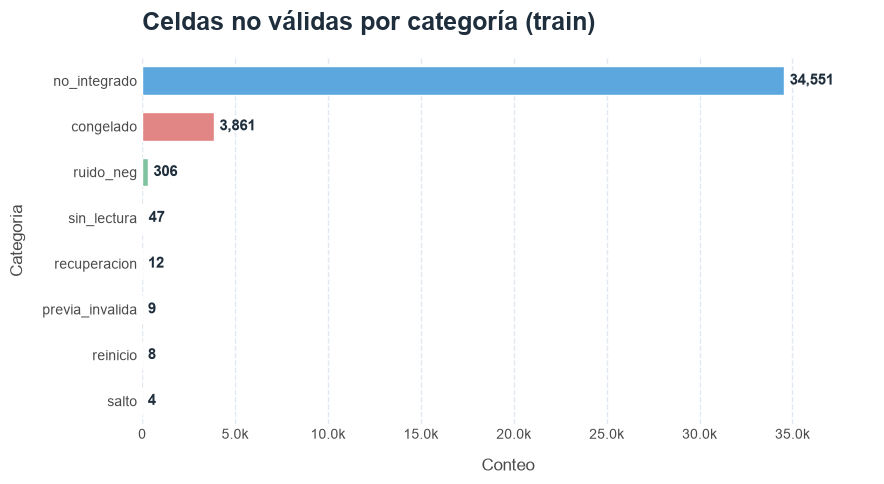

In [51]:
largo = flag.melt(var_name="medidor", value_name="categoria")
fancy_bars(
    largo[largo.categoria != "ok"],
    "categoria",
    labels="count",
    orient="h",
    figsize=(9, 5),
    title="Celdas no válidas por categoría (train)",
)
plt.show()

### 5.1 Patrones: ¿cuándo faltan los datos?

Un mapa por mes muestra si el faltante es estructural (por ejemplo, medidores no integrados), si llega en ráfagas (congelamientos) o si está disperso.

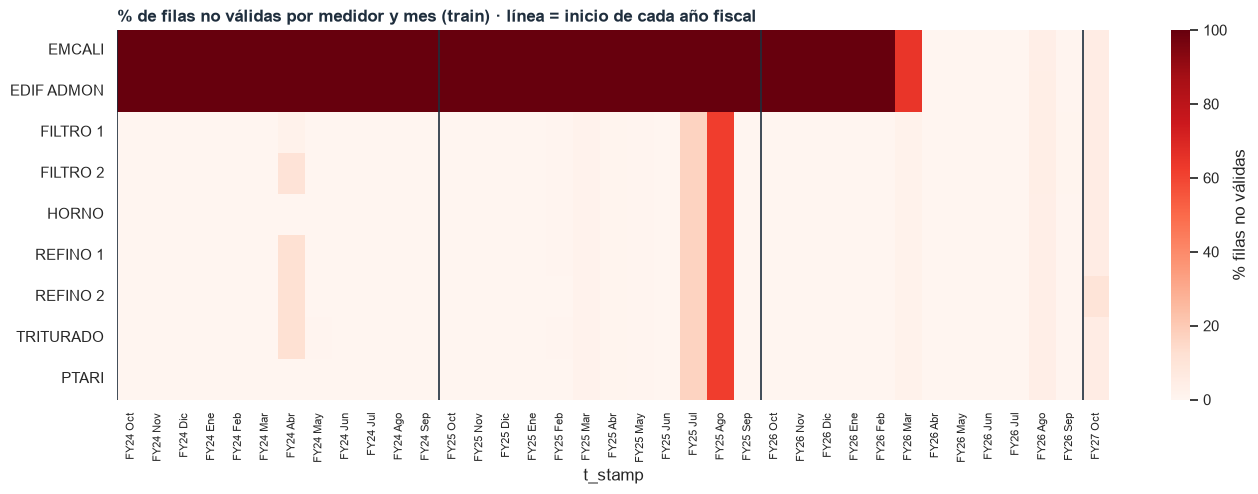

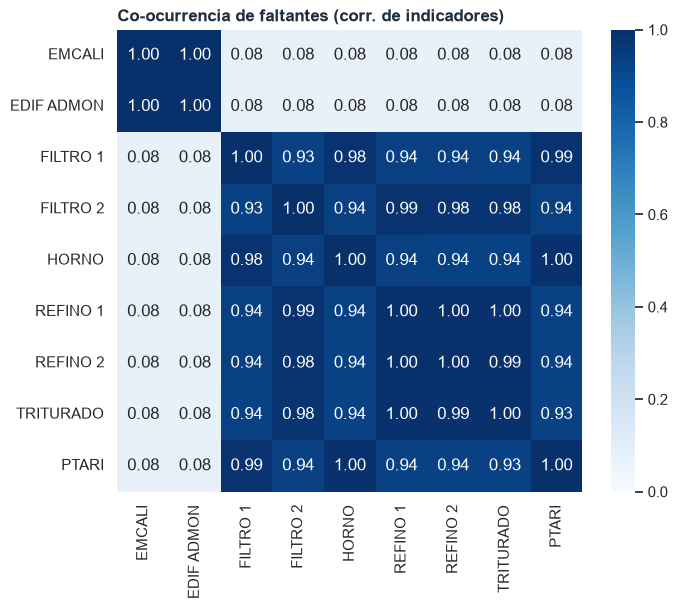

In [52]:
invalido = ~flag.isin(["ok"])
mapa = invalido.groupby(invalido.index.to_period("M")).mean() * 100
fig, ax = plt.subplots(figsize=(16, 4.8))
sns.heatmap(mapa.T, cmap="Reds", vmin=0, vmax=100, ax=ax, cbar_kws={"label": "% filas no válidas"})
ax.set_title(
    "% de filas no válidas por medidor y mes (train) · línea = inicio de cada año fiscal",
    loc="left",
    fontweight="bold",
    color=INK,
)
ax.set_xticklabels(
    [
        f"{e} {NOMBRE_MES[p.month]}"
        for e, p in zip(etiqueta_fy(anio_fiscal(mapa.index)), mapa.index, strict=True)
    ],
    rotation=90,
    fontsize=8,
)
for i, p in enumerate(mapa.index):  # línea al inicio de cada año fiscal
    if p.month == FY_INICIO:
        ax.axvline(i, color=INK, lw=1.2)
plt.show()

co = invalido.astype(int).corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(co, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title(
    "Co-ocurrencia de faltantes (corr. de indicadores)", loc="left", fontweight="bold", color=INK
)
plt.show()

- EMCALI y EDIF ADMON fallan al mismo tiempo, mientras que las otras máquinas del proceso (filtros, hornos, refinos) fallan juntas.

- El mapa de calor nos muestra una franja roja para EMCALI y EDIF ADMON desde el inicio de los datos hasta aproximadamente febrero-marzo del 2026, lo que nos puede mostrar que los medidores no estaban dañados, sino que fueron instalados mucho después que el resto

- También podemos ver que al momento de fallar, no se dañan de forma individual, lo podemos ver con la franja vertical naranja que atraviesa todos los medidores de proceso, esto nos muestra una desconexión general del SCADA o un mantenimiento en donde los sensores dejaron de reportar a la vez

In [53]:
# Rachas de congelamiento general en train (filas train consecutivas en el tiempo real)
c = train["congelado_general"]
contiguo = train["paso_h"].round(2).eq(1)  # la fila anterior real también está en train
bloque = (~(c & c.shift(fill_value=False) & contiguo)).cumsum()
rachas = (
    train[c]
    .groupby(bloque[c])
    .apply(
        lambda g: pd.Series(
            {
                "inicio": g.index.min(),
                "fin": g.index.max(),
                "horas_aprox": (g.index.max() - g.index.min()).total_seconds() / 3600 + 1,
            }
        )
    )
)
rachas = rachas.sort_values("horas_aprox", ascending=False).reset_index(drop=True)
display(rachas.head(8))
print("horas_aprox = cuanto duró el 'apagón")

# chi-cuadrado del indicador de faltante de proceso contra mes, día y hora
falta_proc = invalido[PROCESO].any(axis=1)
filas = []
for nombre, cat in {
    "mes": train.index.to_period("M").astype(str),
    "dia_semana": train.index.dayofweek,
    "hora": train.index.hour,
}.items():
    tabla = pd.crosstab(cat, falta_proc)
    chi2, p, gl, _ = stats.chi2_contingency(tabla)
    v = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    filas.append(
        {
            "faltante vs": nombre,
            "chi2": chi2,
            "gl": gl,
            "p_valor": p,
            "V de Cramér": v,
            "¿caidas aleatorias?": "NO" if p < ALPHA else "SI",
        }
    )
display(pd.DataFrame(filas))

,inicio,fin,horas_aprox
0,2025-07-26 22:30:57.042,2025-08-20 07:30:55.287,586.00
1,2026-08-10 08:30:24.655,2026-08-11 10:30:24.655,27.00
2,2026-03-01 06:30:41.394,2026-03-01 19:30:41.355,14.00
3,2025-03-21 12:31:06.216,2025-03-21 17:31:06.201,6.00
4,2026-09-20 08:30:24.655,2026-09-20 11:30:24.655,4.00
5,2025-04-25 12:31:03.696,2025-04-25 14:31:03.690,3.00
6,2025-03-21 23:31:06.183,2025-03-22 01:31:06.177,3.00
7,2025-05-23 11:31:01.683,2025-05-23 13:31:01.677,3.00


horas_aprox = cuanto duró el 'apagón


,faltante vs,chi2,gl,p_valor,V de Cramér,¿caidas aleatorias?
0,mes,"8,211.01",36,0.00,0.62,NO
1,dia_semana,27.78,6,0.00,0.04,NO
2,hora,8.69,23,1.00,0.02,SI


**Lectura final:**

El análisis de datos faltantes revela tres comportamientos distintos.

- EMCALI y EDIF ADMON faltan de forma estructural antes de mar-2026 (`no_integrado`). No hay nada que imputar, la variable simplemente no existía.

- Las pérdidas de información en la planta ocurren en apagones simultáneos para todas las máquinas, confirmando que es una falla de conexión del SCADA y no sensores dañados. Estos apagones no son aleatorios: Se puede ver que se concentran en ciertos meses del año, aunque no siguen un patrón de días u horas. El más largo (del 26 de julio hasta el 20 de agosto 2025) cae al cierre del FY25 (meses fiscales 10 y 11).

- Los pequeños consumos negativos (ruido_neg) ocurren de forma aislada en cada máquina debido a los problemas de redondeo matemático del sistema, por lo que no representan una pérdida real de información, sino un simple ruido a filtrar.



## 6. Integridad temporal y frecuencia (train)

`paso_h` se calculó antes de dividir los datos, mantiene el tiempo real entre mediciones físicas, evitando errores aunque la fila anterior haya quedado en el set de test.

In [54]:
# se realiza un chequeo de "salud" sobre la linea del tiempo
# para asegurar una estructura temporal solida
paso = train["paso_h"]
print("revisión de integridad temporal del dataset:")
integridad = pd.Series(
    {
        "inicio": train.index.min(),
        "fin": train.index.max(),
        "orden cronológico (tras ordenar)": train.index.is_monotonic_increasing,
        "timestamps duplicados": int(train.index.duplicated().sum()),
        "paso mediano (h)": round(paso.median(), 4),
        "% filas con paso ~ 1 h": round(paso.round(2).eq(1).mean() * 100, 2),
        "filas con paso < 0,95 h": int((paso < PASO_MIN_H).sum()),
        "filas con paso > 1,5 h (huecos)": int((paso > PASO_MAX_H).sum()),
        "zona horaria": "naive (sin tz) — asumir America/Bogota, sin horario de verano",
    }
)
display(integridad.to_frame("valor"))

print("Minuto de la lectura (deriva del reloj del SCADA):")
display(train.index.minute.value_counts().head(6).to_frame("filas").T)

cobertura = train.groupby(train.index.to_period("M")).size().to_frame("filas_train")
horas_mes = cobertura.index.map(lambda p: p.days_in_month * 24)
cobertura["% de horas del mes en train"] = cobertura["filas_train"] / horas_mes * 100
display(cobertura.describe().T)

# Cobertura de train por año fiscal (el FY27 solo tendría la lectura de cierre del 1-oct-2026)
fy_cob = anio_fiscal(cobertura.index)
cob_fy = cobertura.groupby(fy_cob)["filas_train"].agg(meses="size", filas_train="sum")
cob_fy["% de horas del FY en train"] = cob_fy["filas_train"] / cob_fy.index.map(horas_fy) * 100
cob_fy.index = pd.Index(etiqueta_fy(cob_fy.index), name="FY")
display(cob_fy)

revisión de integridad temporal del dataset:


,valor
inicio,2023-10-01 19:31:44.859000
fin,2026-10-01 19:46:24.808000
orden cronológico (tras ordenar),True
timestamps duplicados,0
paso mediano (h),1.00
% filas con paso ~ 1 h,99.98
"filas con paso < 0,95 h",3
"filas con paso > 1,5 h (huecos)",0
zona horaria,"naive (sin tz) — asumir America/Bogota, sin ho..."


Minuto de la lectura (deriva del reloj del SCADA):


t_stamp,31,30,15,1,46
filas,11923,9118,1,1,1


,count,mean,std,min,25%,50%,75%,max
filas_train,37.00,568.76,95.24,19.00,577.00,586.00,599.00,610.00
% de horas del mes en train,37.00,77.83,12.80,2.55,78.76,80.14,80.97,81.99


,meses,filas_train,% de horas del FY en train
FY,,,
FY24,12,6995,79.63
FY25,12,7019,80.13
FY26,12,7011,80.03
FY27,1,19,0.22


**Lectura final:**

La serie cubre tres años fiscales completos: FY24 (oct-2023 → sep-2024), FY25 y FY26 (oct-2025 → sep-2026), también está ordenada y sin fechas duplicadas.

Empieza el 1-oct-2023 a las 19:31 y termina el 1-oct-2026 a las 19:46, así que, aproximadament elas 20 horas del 1-oct-2026 (19 filas en train) pertenecen al FY27 y no se usan en el análisis anual. También podemos observar que el 99,98 % de las filas tienen 1 hora de diferencia entre sí, sin huecos mayores a 1,5 h. Los minutos de la lectura muestran que la mayor parte de las filas están en los minutos 30-31 debido a que probablemente el SCADA está programado para hacer un "barrido" de datos automático a la mitad de cada hora.

Se pueden ver unos pequeños desfases hacia 15, 01 y 46, debido a estos pequeños desplazamientos en los minutos, el pipeline deberá alinear los datos a una grilla horaria exacta (floor('h') o resample) antes de unirlos con otras fuentes. Finalmente, la media de cobertura mensual ronda el ~80%, lo cual tiene sentido con el split realizado de train-test; esto asegura que cada mes conserve suficientes datos y la estacionalidad quede bien representada para el modelo.


## 7. Estacionalidad (train)

Se busca descubrir los ritmos y patrones del consumo de la planta, para revisar en qué momentos se consume más energía y cuando se tienen picos.

Para ello, se usa el consumo horario **válido** (`ok`) del total de los medidores de proceso (`TOTAL_PROCESO`, disponible en todo el periodo). El turno se asigna según el punto medio del intervalo.



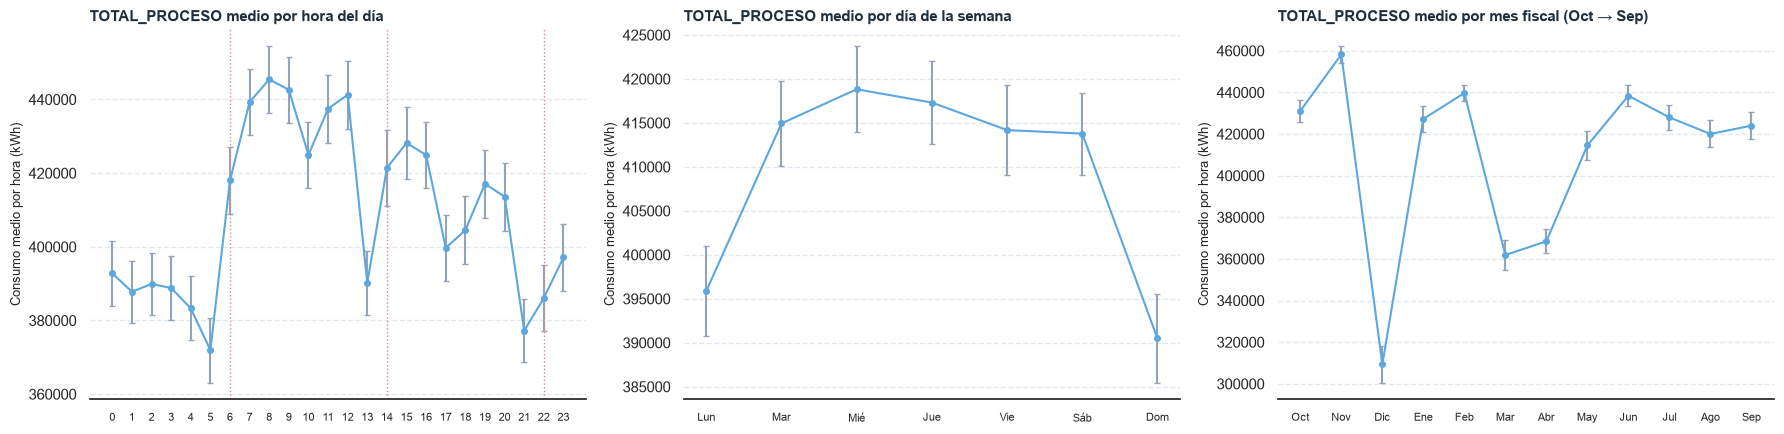

In [55]:
cons_ok = D.where(flag.eq("ok"))
ts = pd.DataFrame(index=train.index)
ts["TOTAL_PROCESO"] = cons_ok[PROCESO].sum(axis=1, min_count=len(PROCESO))
t_mid = train.index.to_series() - pd.to_timedelta(train["paso_h"].fillna(1) / 2, unit="h")
ts["hora"] = t_mid.dt.hour
ts["turno"] = pd.Categorical(
    np.select([ts.hora.ge(22) | ts.hora.lt(6), ts.hora.lt(14)], ["T1", "T2"], "T3"),
    ["T1", "T2", "T3"],
)
ts["dia_semana"] = pd.Categorical(t_mid.dt.dayofweek.map(dict(enumerate(DIAS))), DIAS)
ts["mes"] = pd.Categorical(t_mid.dt.month.map(NOMBRE_MES), MESES_FY)  # orden fiscal Oct → Sep
ts["FY"] = anio_fiscal(pd.DatetimeIndex(t_mid))
ts["FY_label"] = pd.Categorical(etiqueta_fy(ts["FY"]))
ts["mes_fiscal"] = mes_fiscal(pd.DatetimeIndex(t_mid))
ts["anio_mes"] = t_mid.dt.to_period("M")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (col, titulo) in zip(
    axes,
    [
        ("hora", "por hora del día"),
        ("dia_semana", "por día de la semana"),
        ("mes", "por mes fiscal (Oct → Sep)"),
    ],
    strict=True,
):
    g = ts.groupby(col, observed=True)["TOTAL_PROCESO"]
    ax.set_ylabel("Consumo medio por hora (kWh)", fontsize=9)
    m, s = g.mean(), g.sem() * 1.96
    ax.errorbar(
        range(len(m)),
        m.values,
        yerr=s.values,
        marker="o",
        ms=4,
        color="#5BA7DE",
        ecolor="#94a3b8",
        capsize=2,
    )
    ax.set_xticks(range(len(m)))
    ax.set_xticklabels(m.index.astype(str), fontsize=8)
    ax.set_title(
        f"TOTAL_PROCESO medio {titulo}", loc="left", fontweight="bold", color=INK, fontsize=11
    )
    ax.grid(axis="y", color=GRID, ls="--")
    sns.despine(ax=ax, left=True)
for h in (6, 14, 22):
    axes[0].axvline(h, color="#E28585", ls=":", lw=1)
plt.tight_layout()
plt.show()

**lectura por hora:**

- Podemos obseervar que el turno de noche es el que tiene menor consumo de energía, rondando entre los 380.000-400.000 kWh, mientras que el que más tiene s el de la mañana
- Hay un pico a las 6a.m posinlemente de arranque, manteniendo el consumo muy alto toda la mañana (casi siempre por encima de 420.000kWh)
- Hay una caida pronunciada a la 1p.m (horario que normalmente es una hora de almuerzo), en donde varias máquinas bajan su ritmo o pausan su funcionamiento
- Hay caidas de consumo antes de cada final de jornada.

**lectura por día**
- El domingo es el día que menor consumo operativo tiene, cayendo a los 390.000kWh
- El lunes inicia con un consumo moderado y a medida que avanza la semana, la planta alcanza su máxima caapcidad de producción, más específicamente entre los días miércoles y jueves, superando los 415.000 kWh

**lectura por mes**

- Noviembre (2do mes del FY) es el mes con mayor exigencia para la planta tiene el pico más alto, casi llegando a 460.000 kWh.

- El primer trimestre fiscal (Oct–Dic) cierra con el punto más bajo del año, diciembre, cerca de los 320.000 kWh, lo cuál tiene sentido por vacaciones y festividades de fin de año, o, por posibles mantenimientos.

- También se ve una segunda caída en marzo y abril (meses 6 y 7 del FY), lo que también suele coincidir con meses con varios festivos (ej:semana santa).

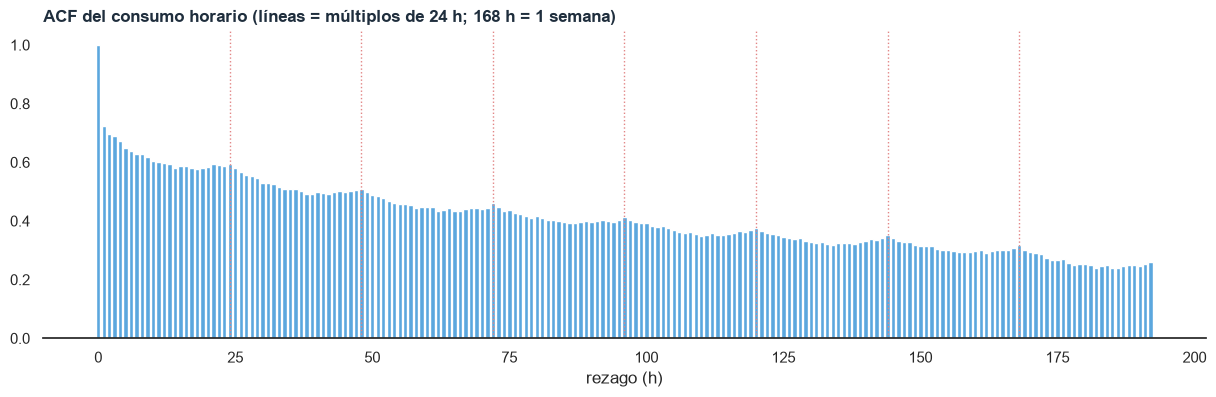

,lag 1 h,lag 8 h,lag 12 h,lag 24 h,lag 168 h
ACF,0.72,0.63,0.60,0.59,0.32


In [56]:
# Autocorrelación sobre la grilla horaria (las horas de test y no válidas quedan como NaN)
grilla = ts["TOTAL_PROCESO"].copy()
grilla.index = grilla.index.floor(
    "h"
)  # deja las horas en formato datetime, sin minutos ni segundos
grilla = grilla[~grilla.index.duplicated()].asfreq(
    "h"
)  # se rellena con NaN las horas que no están en train (test o huecos)
r = acf(
    grilla, nlags=24 * 8, missing="conservative"
)  # correlación de la serue con respecto a sí misma, hasta 8 días (24 h * 8)
fig, ax = plt.subplots(figsize=(15, 4))
ax.bar(range(len(r)), r, color="#5BA7DE", width=0.8)
for k in (24, 48, 72, 96, 120, 144, 168):
    ax.axvline(k, color="#E28585", ls=":", lw=1)
ax.set_title(
    "ACF del consumo horario (líneas = múltiplos de 24 h; 168 h = 1 semana)",
    loc="left",
    fontweight="bold",
    color=INK,
)
ax.set_xlabel("rezago (h)")
sns.despine(left=True)
plt.show()
display(pd.Series({f"lag {k} h": r[k] for k in (1, 8, 12, 24, 168)}).to_frame("ACF").T)

**Rezago:** número de periodos de tiempo que separan una observación de otra anterior de la misma serie, usado para medir cuánto se parece un valor a los valores pasados.

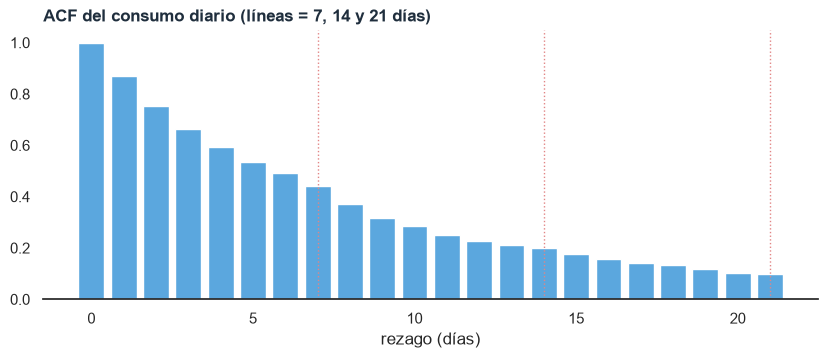

In [57]:
diaria = grilla.resample("D").mean()
r_d = acf(diaria, nlags=21, missing="conservative")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(range(len(r_d)), r_d, color="#5BA7DE")
for k in (7, 14, 21):
    ax.axvline(k, color="#E28585", ls=":", lw=1)
ax.set_title(
    "ACF del consumo diario (líneas = 7, 14 y 21 días)", loc="left", fontweight="bold", color=INK
)
ax.set_xlabel("rezago (días)")
sns.despine(left=True)
plt.show()

In [58]:
with warnings.catch_warnings():
    warnings.simplefilter(
        "ignore"
    )  # avisos de formato de statsmodels y del límite de la tabla KPSS
    adf_p = adfuller(diaria.dropna(), autolag="AIC")[1]
    kpss_p = kpss(diaria.dropna(), regression="c", nlags="auto")[1]

print(f"ADF  (H0: NO estacionaria):          p = {adf_p:.4f}")
print(f"KPSS (H0: estacionaria en nivel):    p = {kpss_p:.4f}  (≤ 0,01 = el real es aún menor)")

ADF  (H0: NO estacionaria):          p = 0.0000
KPSS (H0: estacionaria en nivel):    p = 0.0100  (≤ 0,01 = el real es aún menor)


In [59]:
pruebas = hub_pruebas_num_cat(ts, "TOTAL_PROCESO", ["turno", "dia_semana", "mes"])


def eps2(cat: str) -> float:
    """Tamaño del efecto ε² de Kruskal-Wallis del consumo frente a `cat`."""
    sub = ts[["TOTAL_PROCESO", cat]].dropna()
    h = stats.kruskal(
        *[g.values for _, g in sub.groupby(cat, observed=True)["TOTAL_PROCESO"]]
    ).statistic
    return h / (len(sub) - 1)


pruebas["epsilon2"] = pruebas["var_categorica"].map(eps2)
display(pruebas[["var_categorica", "n_grupos", "prueba", "p_valor", "epsilon2", "decision"]])
display(
    ts.groupby("turno", observed=True)["TOTAL_PROCESO"]
    .agg(["count", "mean", "median"])
    .assign(horario=lambda d: d.index.map(TURNOS))
)

,var_categorica,n_grupos,prueba,p_valor,epsilon2,decision
0,turno,3,Kruskal-Wallis (H),0.00,0.03,Se rechaza H0
1,dia_semana,7,Kruskal-Wallis (H),0.00,0.01,Se rechaza H0
2,mes,12,Kruskal-Wallis (H),0.00,0.08,Se rechaza H0


,count,mean,median,horario
turno,,,,
T1,6757,"387,222.92","426,544.00",22:00-06:00
T2,6819,"430,003.95","457,280.00",06:00-14:00
T3,6830,"410,856.55","440,792.00",14:00-22:00


**Lectura final:**
- **Ciclo diario por turnos:** el consumo sube en T2 (07–12 h) y cae justo antes de cada relevo (05, 13 y 21 h).

- **Día de la semana:** domingo y lunes son los días más bajos, pero el efecto es pequeño (ε² = 0,01) y no se repite como un ciclo semanal en la ACF.

- **Estacionalidad dentro del año fiscal:** diciembre (cierre del Q1 fiscal) y marzo–abril (paso del Q2 al Q3) son claramente más bajos (periodos de operación y parada del horno).

- **Mes:** Es el factor más importante; Al medir matemáticamente qué condiciones alteran más el ritmo de producción, el mes del año resultó ser el más decisivo, sin embargo sigue siendo un efecto bastante débil.

- **Tamaño del efecto (ε²):** de las tres variables de calendario, el mes es la que más diferencia el consumo. Según las convenciones habituales (0,01 pequeño, 0,06 moderado, 0,14 grande), el efecto del mes es moderado; sin embargo, explica solo ~8 % de la variabilidad del consumo, de modo que la mayor parte depende de factores operativos (periodos de operación y parada del horno) más que del calendario. Las pruebas son significativas, pero con tantos datos eso ocurre casi siempre; por eso se compara con el tamaño del efecto.

- **ACF:** el consumo no da saltos bruscos: lo que la planta gasta en una hora se parece mucho a lo que gastó la hora anterior (lag 1 h ~ 0,72). Se ven picos leves (+0,01 a +0,03 sobre las horas vecinas) cada 24h, que reflejan la rutina diaria de la planta; el de 168 h no es más fuerte que los diarios y la ACF diaria lo confirma, debido a que baja de forma suave sin picos en 7, 14 o 21 días, así que no hay ciclo semanal. Lo que sí hay es persistencia: la planta pasa por rachas de varios días con consumo alto o bajo. 

Incluso con una semana de diferencia, el consumo sigue pareciéndose (correlación de 0,32), esto sucede debido a que el consumo promedio de la serie cambia con el tiempo. Las pruebas ADF y KPSS lo confirman, muestran que el consumo tiende a volver a su promedio, pero ese promedio no es fijo y cambia con periodos de operación y parada y también entre años fiscales, así que la serie no es estacionaria.

- **Para el modelo:** conviene usar información del pasado reciente ("ayer a esta hora", promedio de los últimos días) junto con variables de calendario (turno, día de la semana y mes). Como además el nivel de consumo baja de un año fiscal a otro, el modelo necesita algo que capture ese cambio de nivel (el año fiscal, una tendencia o desfases largos); si no, sobreestimará el consumo reciente.

### 7.1 Evolución anual por año fiscal (oct → sep)

El año fiscal de la empresa va de octubre a septiembre y se nombra por el año en que termina: **FY24** = oct-2023 → sep-2024, **FY25** = oct-2024 → sep-2025 y **FY26** = oct-2025 → sep-2026. La serie cubre tres años fiscales completos.

Cómo se calcula el total anual:

- Se usa el consumo horario válido (`ok`) de train. Cada hora se asigna al FY de su punto medio, igual que el turno.
- Train tiene ~80 % de las horas y los congelamientos se concentran en ciertos meses (MAR), así que no se suman las horas directamente. Primero se estima cada mes como **media horaria x horas del mes** y después se suman los 12 meses del FY. Un mes con menos de una semana de horas válidas queda sin estimar, y su FY se marca como incompleto (no entra en el YoY).
- La **intensidad** es el consumo medio por hora del FY (kWh/h). No hay datos de producción, así que todavía no se puede calcular kWh por unidad producida.
- EMCALI y EDIF ADMON quedan fuera: solo existen desde mar-2026 (FY26), así que no permiten comparar años.

In [60]:
# Consumo mensual estimado = media horaria válida (train) x horas del mes.
# Se usa la media y no la suma: train tiene ~80 % de las horas (split aleatorio)
# y los congelamientos se concentran en ciertos meses (MAR). Estimar mes a mes
# y luego sumar evita que un FY con más huecos parezca consumir menos.
MIN_HORAS_MES = 24 * 7  # mínimo una semana de horas válidas para estimar un mes
COLS_FY = [*PROCESO, "TOTAL_PROCESO"]

horaria = cons_ok[PROCESO].assign(TOTAL_PROCESO=ts["TOTAL_PROCESO"])
g_mes = horaria.groupby(ts["anio_mes"])
media_mes = g_mes.mean().where(g_mes.count() >= MIN_HORAS_MES)

mensual = media_mes.mul(media_mes.index.days_in_month * 24, axis=0)  # kWh estimados del mes
mensual["horas_validas"] = g_mes["TOTAL_PROCESO"].count()
mensual["horas_mes"] = mensual.index.days_in_month * 24
mensual["FY"] = anio_fiscal(mensual.index)
mensual["mes_fiscal"] = mes_fiscal(mensual.index)

estimado = mensual["TOTAL_PROCESO"].notna()
g_fy = mensual.groupby("FY")
anual = g_fy[COLS_FY].sum(min_count=1)
anual["meses_estimados"] = g_fy["TOTAL_PROCESO"].count()
anual["horas_validas_train"] = g_fy["horas_validas"].sum()
anual["cobertura_%"] = anual["horas_validas_train"] / anual.index.map(horas_fy) * 100
anual["kWh/h medio"] = (
    anual["TOTAL_PROCESO"] / mensual["horas_mes"].where(estimado).groupby(mensual["FY"]).sum()
)
anual = anual[anual["meses_estimados"] > 0].copy()  # descarta colas sin meses estimables
anual["FY_completo"] = anual["meses_estimados"].eq(12)
anual["YoY_%"] = (
    anual["TOTAL_PROCESO"].where(anual["FY_completo"]).pct_change(fill_method=None) * 100
)
anual.index = pd.Index(etiqueta_fy(anual.index), name="FY")

display(
    anual[
        ["meses_estimados", "cobertura_%", "TOTAL_PROCESO", "kWh/h medio", "YoY_%", "FY_completo"]
    ]
)

,meses_estimados,cobertura_%,TOTAL_PROCESO,kWh/h medio,YoY_%,FY_completo
FY,,,,,,
FY24,12,78.69,"3,910,654,914.27","445,202.06",NaN,True
FY25,12,74.34,"3,669,436,462.00","418,885.44",-6.17,True
FY26,12,79.51,"3,195,658,137.86","364,801.16",-12.91,True


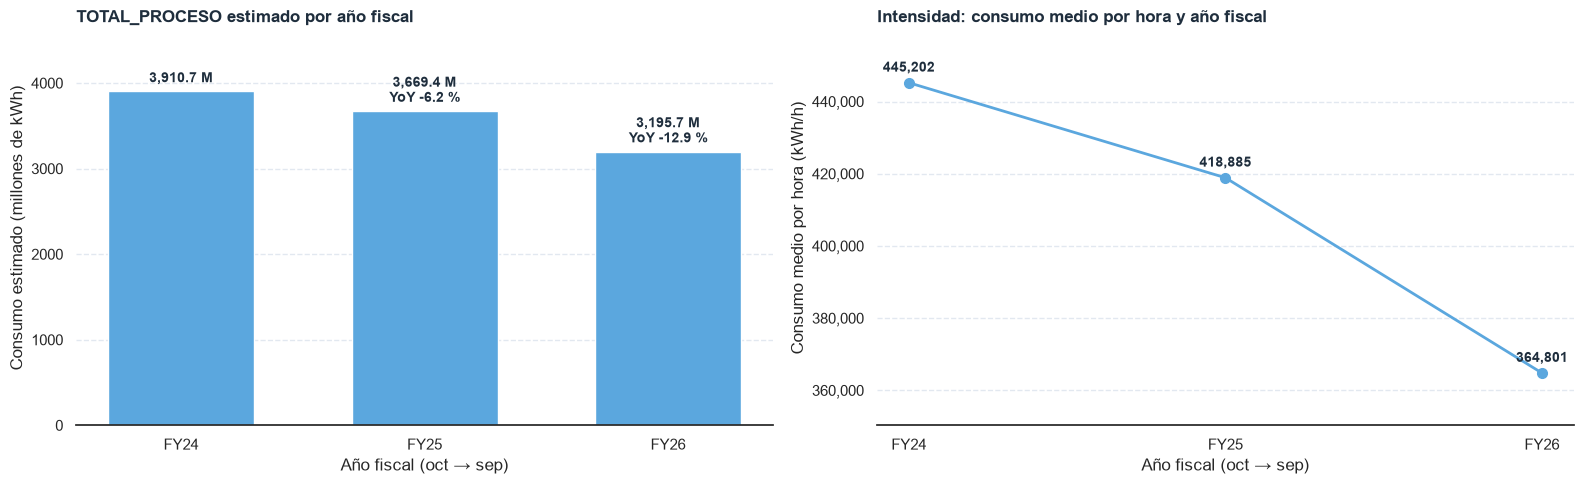

In [61]:
x = np.arange(len(anual))
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

colores = ["#5BA7DE" if c else "#CBD5E1" for c in anual["FY_completo"]]  # gris = FY parcial
barras = axes[0].bar(x, anual["TOTAL_PROCESO"] / 1e6, color=colores, width=0.6)
textos = [
    f"{v / 1e6:,.1f} M" + ("" if np.isnan(y) else f"\nYoY {y:+.1f} %")
    for v, y in zip(anual["TOTAL_PROCESO"], anual["YoY_%"], strict=True)
]
axes[0].bar_label(barras, labels=textos, padding=4, fontsize=10, fontweight="bold", color=INK)
axes[0].set_ylabel("Consumo estimado (millones de kWh)")
axes[0].set_title("TOTAL_PROCESO estimado por año fiscal", loc="left", fontweight="bold", color=INK)

axes[1].plot(x, anual["kWh/h medio"], marker="o", ms=7, color="#5BA7DE", lw=2)
for xi, v in zip(x, anual["kWh/h medio"], strict=True):
    axes[1].annotate(
        f"{v:,.0f}",
        (xi, v),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=INK,
    )
axes[1].set_ylabel("Consumo medio por hora (kWh/h)")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[1].set_title(
    "Intensidad: consumo medio por hora y año fiscal", loc="left", fontweight="bold", color=INK
)

for ax in axes:
    ax.set_xticks(x, anual.index)
    ax.set_xlabel("Año fiscal (oct → sep)")
    ax.margins(y=0.18)
    ax.grid(axis="y", color=GRID, ls="--")
    sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()

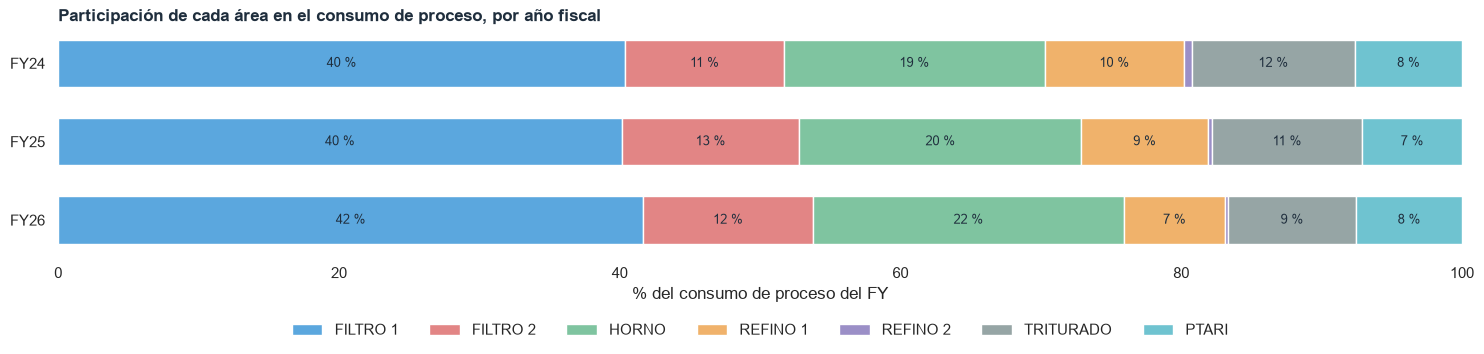

,FILTRO 1,FILTRO 2,HORNO,REFINO 1,REFINO 2,TRITURADO,PTARI
FY,,,,,,,
FY24,40.40,11.30,18.60,9.90,0.50,11.70,7.60
FY25,40.20,12.70,20.10,9.00,0.30,10.70,7.10
FY26,41.70,12.10,22.20,7.20,0.20,9.20,7.50


In [62]:
mezcla = anual[PROCESO].div(anual[PROCESO].sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(15, 1.2 + 0.9 * len(mezcla)))
MIN_PCT_ETIQUETA = 4  # no rotular franjas de menos de 4 %
izq = np.zeros(len(mezcla))
for col, color in zip(PROCESO, PALETTE, strict=False):
    ax.barh(mezcla.index, mezcla[col], left=izq, color=color, label=col, height=0.6)
    for y, (base, v) in enumerate(zip(izq, mezcla[col], strict=True)):
        if v >= MIN_PCT_ETIQUETA:
            ax.text(base + v / 2, y, f"{v:.0f} %", ha="center", va="center", fontsize=9, color=INK)
    izq += mezcla[col].to_numpy()
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% del consumo de proceso del FY")
ax.set_title(
    "Participación de cada área en el consumo de proceso, por año fiscal",
    loc="left",
    fontweight="bold",
    color=INK,
)
ax.legend(ncol=len(PROCESO), loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
sns.despine(ax=ax, left=True, bottom=True)
plt.tight_layout()
plt.show()
display(mezcla.round(1))

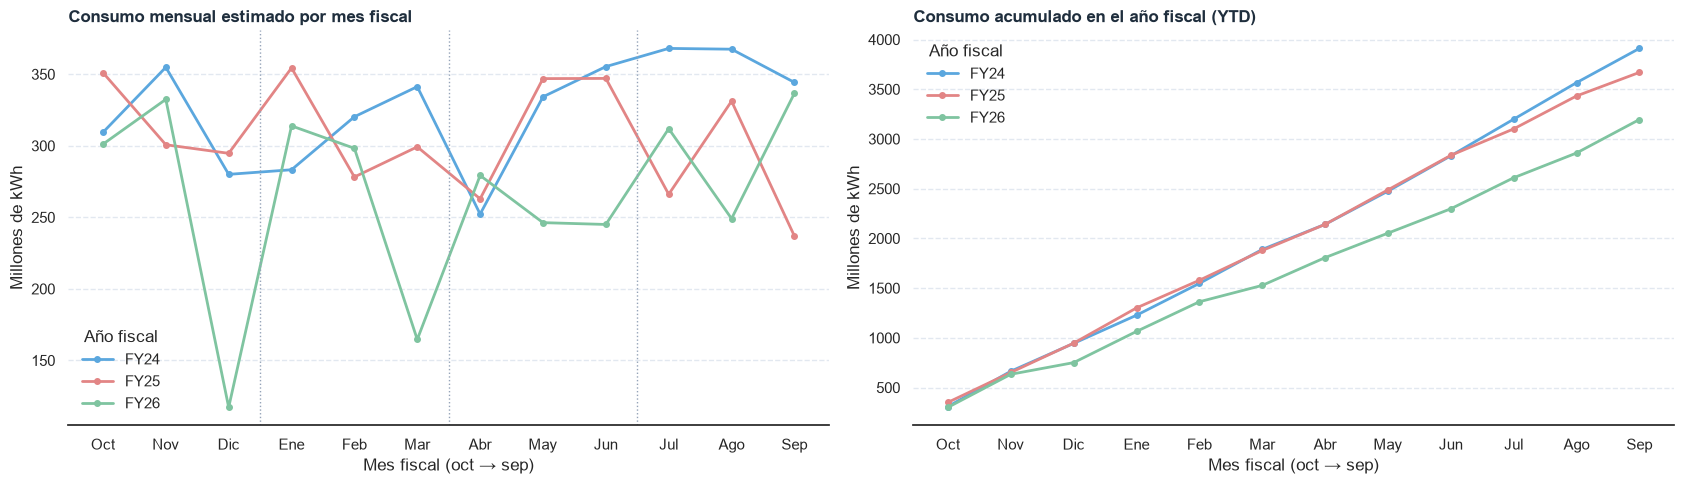

,Oct,Nov,Dic,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep
FY24,309.36,354.85,280.02,283.23,320.28,341.31,252.25,334.20,355.32,368.04,367.49,344.28
FY25,351.12,300.71,294.72,354.40,278.19,299.24,262.92,346.93,347.07,266.08,331.17,236.89
FY26,301.11,332.44,117.19,313.89,298.21,164.62,279.24,246.27,245.00,311.95,249.06,336.68


In [63]:
# Trayectoria dentro del año fiscal: mismo mes fiscal, distintos FY
tray = mensual.pivot(index="mes_fiscal", columns="FY", values="TOTAL_PROCESO").reindex(range(1, 13))
tray.columns = etiqueta_fy(tray.columns)
tray = tray[anual.index]  # solo los FY de la tabla anual

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for fy, color in zip(tray.columns, PALETTE, strict=False):
    axes[0].plot(tray.index, tray[fy] / 1e6, marker="o", ms=4, color=color, lw=2, label=fy)
    axes[1].plot(tray.index, tray[fy].cumsum() / 1e6, marker="o", ms=4, color=color, lw=2, label=fy)
axes[0].set_title(
    "Consumo mensual estimado por mes fiscal", loc="left", fontweight="bold", color=INK
)
axes[1].set_title(
    "Consumo acumulado en el año fiscal (YTD)", loc="left", fontweight="bold", color=INK
)
for ax in axes:
    ax.set_xticks(range(1, 13), MESES_FY)
    ax.set_xlabel("Mes fiscal (oct → sep)")
    ax.set_ylabel("Millones de kWh")
    ax.grid(axis="y", color=GRID, ls="--")
    ax.legend(title="Año fiscal", frameon=False)
    sns.despine(ax=ax, left=True)
for q in (3.5, 6.5, 9.5):  # cortes de trimestre fiscal
    axes[0].axvline(q, color="#94a3b8", ls=":", lw=1)
plt.tight_layout()
plt.show()
display((tray / 1e6).round(2).set_axis(MESES_FY).T)

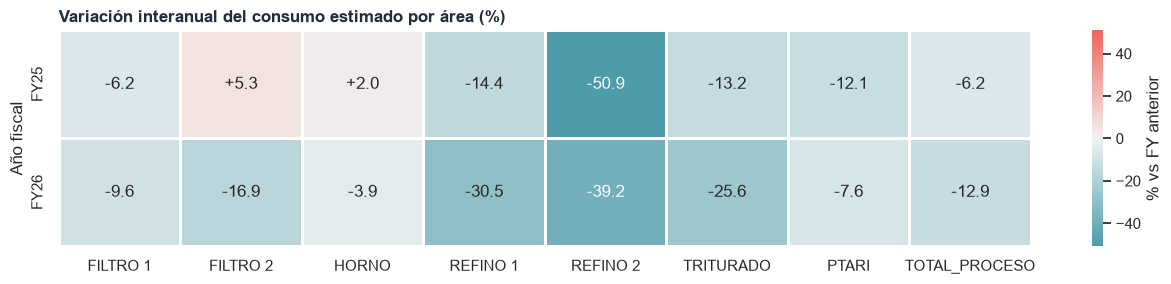

In [64]:
# Variación interanual por área (solo entre FY completos)
yoy_area = anual[COLS_FY].where(anual["FY_completo"], axis=0).pct_change(fill_method=None) * 100
yoy_area = yoy_area.dropna(how="all")

fig, ax = plt.subplots(figsize=(13, 1.4 + 0.8 * len(yoy_area)))
lim = np.nanmax(np.abs(yoy_area.to_numpy()))
sns.heatmap(
    yoy_area,
    annot=True,
    fmt="+.1f",
    center=0,
    vmin=-lim,
    vmax=lim,
    cmap=sns.diverging_palette(210, 15, s=75, l=60, as_cmap=True),
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "% vs FY anterior"},
    ax=ax,
)
ax.set_title(
    "Variación interanual del consumo estimado por área (%)",
    loc="left",
    fontweight="bold",
    color=INK,
)
ax.set_xlabel("")
ax.set_ylabel("Año fiscal")
plt.tight_layout()
plt.show()

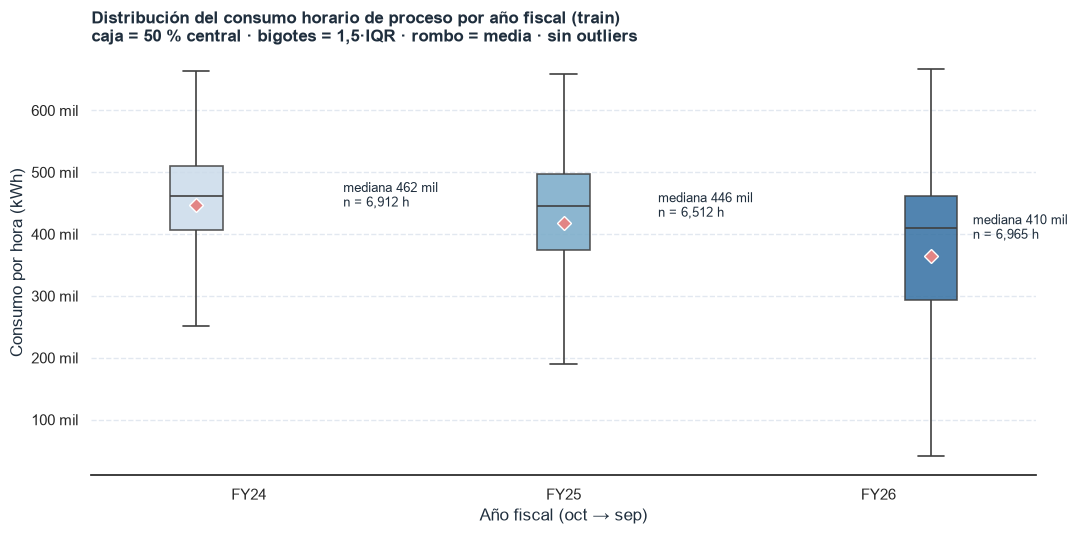

,var_categorica,n_grupos,prueba,p_valor,epsilon2,decision,post_hoc
0,FY_label,3,Kruskal-Wallis (H),0.00,0.07,Se rechaza H0,FY24 vs FY25 (p=0.0000); FY24 vs FY26 (p=0.000...


In [65]:
# ¿Cambia el nivel de consumo horario entre años fiscales?
ts_fy = ts[ts["FY_label"].isin(anual.index)].copy()
ts_fy["FY_label"] = ts_fy["FY_label"].cat.remove_unused_categories()

fig, ax = plt.subplots(figsize=(11, 5.5))
orden = list(ts_fy["FY_label"].cat.categories)
sns.boxplot(
    data=ts_fy,
    x="FY_label",
    y="TOTAL_PROCESO",
    order=orden,
    hue="FY_label",
    hue_order=orden,
    palette="Blues",
    legend=False,
    width=0.5,
    linewidth=1.2,
    showfliers=False,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "#E28585",
        "markeredgecolor": "white",
        "markersize": 7,
    },
    boxprops={"alpha": 0.85},
    ax=ax,
)
res = ts_fy.groupby("FY_label", observed=True)["TOTAL_PROCESO"].agg(["median", "count"])
for i, fy in enumerate(orden):
    ax.text(
        i + 0.3,
        res.loc[fy, "median"],
        f"mediana {res.loc[fy, 'median'] / 1e3:,.0f} mil\nn = {res.loc[fy, 'count']:,} h",
        va="center",
        fontsize=9,
        color=INK,
    )
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e3:,.0f} mil"))
ax.set_xlabel("Año fiscal (oct → sep)", color=INK)
ax.set_ylabel("Consumo por hora (kWh)", color=INK)
ax.set_title(
    "Distribución del consumo horario de proceso por año fiscal (train)\n"
    "caja = 50 % central · bigotes = 1,5·IQR · rombo = media · sin outliers",
    loc="left",
    fontweight="bold",
    color=INK,
    fontsize=12,
)
ax.grid(axis="y", color=GRID, ls="--")
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()

prueba_fy = hub_pruebas_num_cat(ts_fy, "TOTAL_PROCESO", "FY_label")
sub = ts_fy[["TOTAL_PROCESO", "FY_label"]].dropna()
h = stats.kruskal(
    *[g.to_numpy() for _, g in sub.groupby("FY_label", observed=True)["TOTAL_PROCESO"]]
).statistic
prueba_fy["epsilon2"] = h / (len(sub) - 1)
display(
    prueba_fy[
        ["var_categorica", "n_grupos", "prueba", "p_valor", "epsilon2", "decision", "post_hoc"]
    ]
)

**Lectura (año fiscal):**

- **Total anual:** TOTAL_PROCESO pasó de 3.910,7 M kWh en FY24 a 3.669,4 M en FY25 (YoY −6,2 %) y a 3.195,7 M en FY26 (YoY −12,9 %). En dos años fiscales el consumo de proceso cayó ~18 %, y la caída se aceleró en el FY26.

- **Intensidad:** el consumo medio por hora fue 445.202 kWh/h en FY24, 418.885 en FY25 y 364.801 en FY26. Baja de forma sostenida (−18 % entre FY24 y FY26). Los tres FY tienen los 12 meses estimados, así que la caída no viene de huecos en los datos: la planta consumió menos por hora.

- **FY25 y el congelamiento:** el apagón del SCADA (26-jul → 20-ago-2025) cae en los meses fiscales 10 y 11 del FY25, y por eso FY25 tiene la menor cobertura en train (74,3 % frente a ~79 % de FY24 y FY26). El total se estima con la media de las horas válidas de cada mes, así que el hueco por sí solo no reduce el total. Aun así, **casi toda la caída del FY25 (−241 M kWh) está en su Q4** (jul–sep 2025: 834 M frente a 1.080 M del FY24). Septiembre (237 M, el mes más bajo del FY25) no tuvo congelamiento, así que no todo se explica por el apagón. Conviene validar con la planta qué pasó en el cierre del FY25.

- **Mezcla por área:** **HORNO** es la que más gana participación (18,6 % → 20,1 % → 22,2 %), pero en consumo absoluto se mantiene casi igual (~710–740 M kWh por año). Sube su peso porque el resto cae. Las que más pierden son **REFINO 1** (9,9 % → 7,2 %) y **TRITURADO** (11,7 % → 9,2 %): en consumo absoluto bajan ~40 % y ~36 % entre FY24 y FY26. FILTRO 1 sigue siendo la carga base (~40–42 %), y FILTRO 2 y PTARI se mantienen estables. REFINO 2 es marginal (≤ 0,5 %).

- **Trayectoria dentro del FY:**
  - **Diciembre** es un valle en los tres FY (280, 295 y 117 M kWh). En FY26 es extremo: menos de la mitad de lo normal.
  - **El segundo valle se mueve entre años:** en FY24 y FY25 cae en abril (252 y 263 M); en FY26, en marzo (165 M).
  - **El pico de noviembre no se repite siempre:** aparece en FY24 y FY26, pero en FY25 el mes más alto del Q1 es octubre.
  - **FY26 tiene dos meses atípicos:** diciembre y marzo explican ~2/3 de la caída frente al FY25 (−312 de −474 M kWh). Mayo y junio también quedan ~100 M por debajo cada uno, aunque julio y septiembre compensan en parte.

- **Prueba:** Kruskal-Wallis por FY, p < 0,001, ε² = 0,07. Los tres pares de años son distintos entre sí (post-hoc con Bonferroni, p < 0,001 en todos). El efecto es **moderado** (justo por encima de 0,06): el año fiscal explica ~7 % de la variabilidad del consumo horario, parecido al efecto del mes (~8 %). Hay una tendencia real a la baja entre años, pero la mayor parte de la variación sigue dependiendo de la operación (periodos de operación y parada).

- **Unidades:** los valores se reportan en kWh, pero la unidad sigue pendiente de validar con la planta (podría ser Wh). Los porcentajes, el YoY y la mezcla no dependen de la unidad.

## 8. Distribuciones y outliers (train, solo consumos `ok`)

In [66]:
desc = cons_ok.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
desc["asimetria"] = cons_ok.skew()
desc["curtosis"] = cons_ok.kurt()
desc["% en cero"] = cons_ok.eq(0).sum() / cons_ok.notna().sum() * 100
display(desc)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,asimetria,curtosis,% en cero
EMCALI,"3,718.00","2,082.16",843.23,72.50,"1,055.78","1,164.89","1,553.06","2,021.56","2,516.75","3,012.47","3,689.28","16,116.00",5.21,55.15,0.00
EDIF ADMON,"3,717.00","2,918.74",923.98,0.00,0.00,"1,784.45","2,316.00","2,874.50","3,457.50","4,460.80","4,954.52","16,185.00",0.61,12.28,2.07
FILTRO 1,"20,479.00","166,401.57","53,949.14",0.00,0.00,512.00,"175,104.00","183,296.00","187,904.00","195,584.00","201,728.00","957,952.00",-2.19,9.31,2.31
FILTRO 2,"20,429.00","48,960.23","24,284.72",0.00,0.00,128.00,"57,344.00","60,032.00","61,568.00","65,536.00","70,400.00","318,208.00",-1.28,1.59,3.75
HORNO,"20,494.00","81,785.15","54,700.11",0.00,"1,024.00","1,792.00","7,680.00","101,120.00","124,928.00","147,712.00","165,376.00","808,448.00",-0.17,2.07,0.15
REFINO 1,"20,424.00","36,326.77","25,153.91",0.00,"1,408.00","1,664.00","12,032.00","38,144.00","54,944.00","75,904.00","89,472.00","425,984.00",0.39,3.09,0.12
REFINO 2,"20,424.00","1,418.95","2,428.94",0.00,0.00,0.00,512.00,"1,168.00","1,792.00","2,832.00","3,916.32","38,048.00",10.51,125.94,6.45
TRITURADO,"20,420.00","43,425.30","46,224.34",0.00,"1,024.00","1,280.00","6,656.00","18,176.00","75,520.00","131,328.00","156,367.36","444,160.00",0.98,-0.04,0.13
PTARI,"20,493.00","30,296.57","9,543.15",0.00,"6,912.00","11,904.00","25,216.00","31,488.00","36,736.00","43,520.00","47,488.00","222,720.00",0.16,12.35,0.18


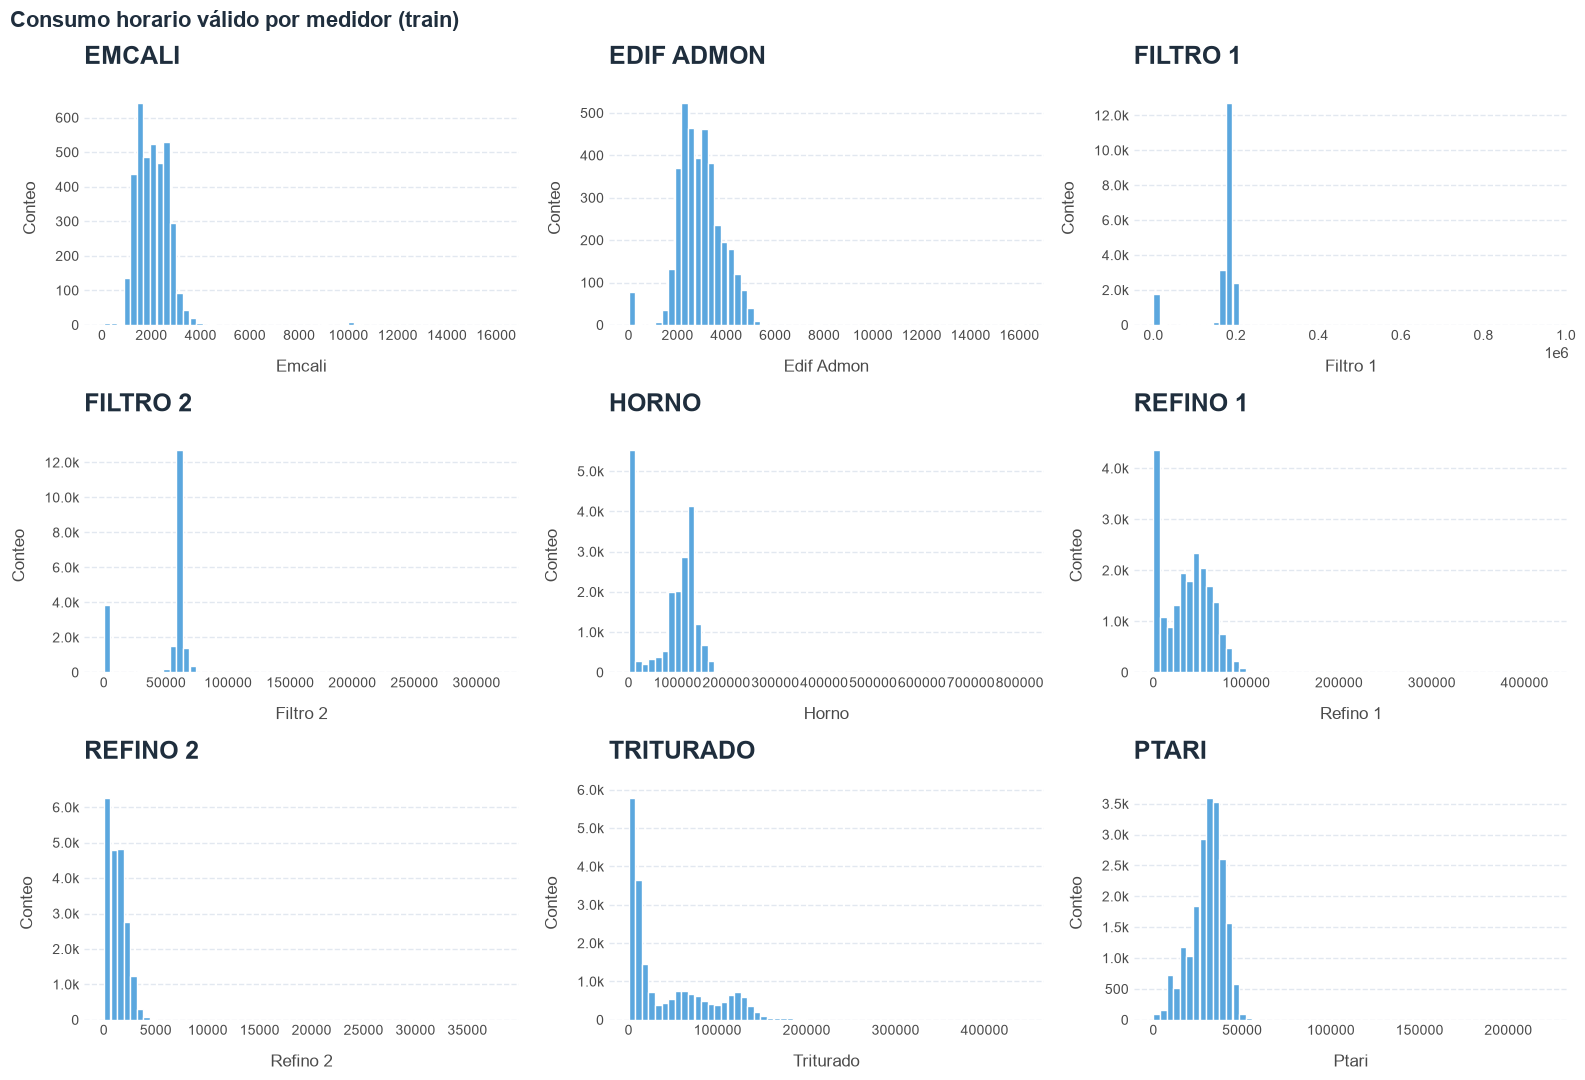

In [67]:
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, m in zip(axes.flat, MEDIDORES, strict=True):
    fancy_hist(cons_ok, m, ax=ax, title=m)
    ax.title.set_fontsize(12)
plt.suptitle(
    "Consumo horario válido por medidor (train)",
    x=0.01,
    ha="left",
    fontsize=16,
    fontweight="bold",
    color=INK,
)
plt.tight_layout()
plt.show()

,n,% Tukey bajo,% Tukey alto,"% |z_MAD| > 3,5",máx / p99
medidor,,,,,
EMCALI,3718,0.08,0.73,0.59,4.37
EDIF ADMON,3717,2.18,0.30,0.05,3.27
FILTRO 1,20479,10.47,0.22,10.31,4.75
FILTRO 2,20429,21.28,2.80,23.01,4.52
HORNO,20494,0.00,0.02,0.03,4.89
REFINO 1,20424,0.00,0.04,0.02,4.76
REFINO 2,20424,0.00,1.20,0.77,9.72
TRITURADO,20420,0.00,0.42,16.30,2.84
PTARI,20493,1.41,0.10,0.31,4.69


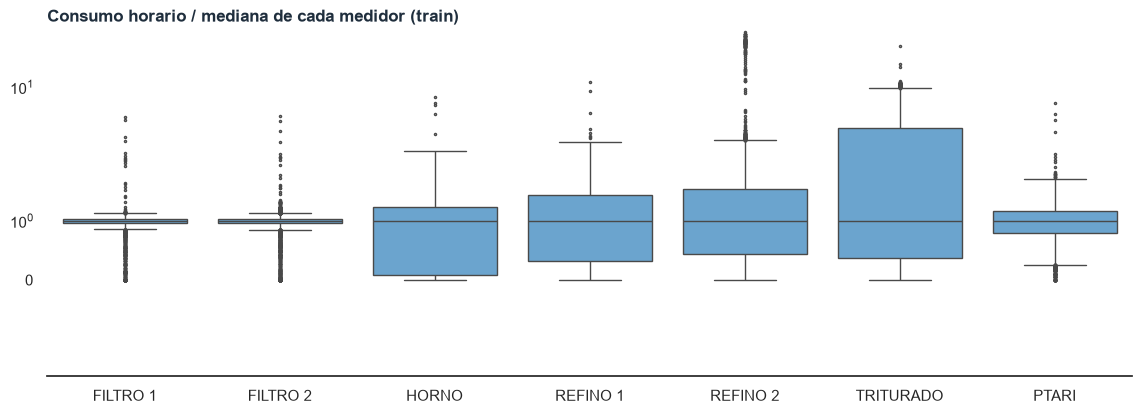

In [68]:
# Outliers: regla de Tukey (1,5·IQR) y z robusto (MAD > 3,5)
out = []
for m in MEDIDORES:
    s = cons_ok[m].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    mad = stats.median_abs_deviation(s, scale="normal")
    z = (s - s.median()) / mad if mad > 0 else pd.Series(0, index=s.index)
    out.append(
        {
            "medidor": m,
            "n": len(s),
            "% Tukey bajo": (s < q1 - 1.5 * iqr).mean() * 100,
            "% Tukey alto": (s > q3 + 1.5 * iqr).mean() * 100,
            "% |z_MAD| > 3,5": (z.abs() > Z_MAD_UMBRAL).mean() * 100,
            "máx / p99": s.max() / s.quantile(0.99),
        }
    )
outliers = pd.DataFrame(out).set_index("medidor")
display(outliers)

fig, ax = plt.subplots(figsize=(14, 4.5))
norm = cons_ok[PROCESO] / cons_ok[PROCESO].median()
sns.boxplot(data=norm, ax=ax, color="#5BA7DE", fliersize=1.5, linewidth=1)
ax.set_title(
    "Consumo horario / mediana de cada medidor (train)", loc="left", fontweight="bold", color=INK
)
ax.set_yscale("symlog")
sns.despine(left=True)
plt.show()

findfont: Failed to find font weight medium for Arial, now using 400.


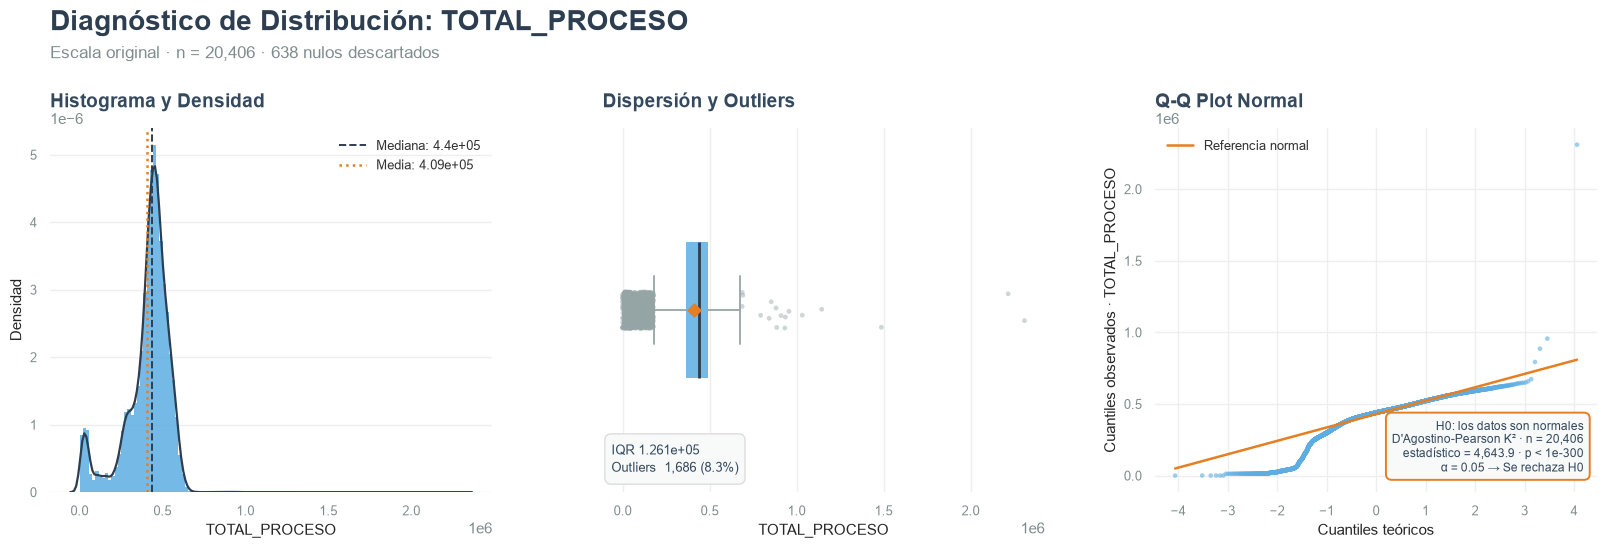

In [69]:
rep = normality_report(ts, "TOTAL_PROCESO")

**Lectura:**


- Las distribuciones son multimodales (operación / parada) y con asimetría negativa en el total:

    * HORNO: Su percentil 25% es de apenas 7,680, pero su mediana salta a 101,120. Esta enorme diferencia comprueba que la máquina pasa al menos una cuarta parte del tiempo apagada o al mínimo, y luego opera a niveles altísimos.

    * TRITURADO: Su desviación estándar supera a su propio promedio y tiene el boxplot más ancho de todos. Su histograma muestra varias crestas, lo que refleja los constantes cambios de intensidad a lo largo de los distintos turnos.

    * Filtros: Representan la carga base de la planta, manteniendo una distribución estrecha y un consumo constante.

- Los "outliers bajos" son mayormente paradas reales y no errores, y los altos extremos son pocos una vez se excluyen saltos y recuperaciones. No conviene recortarlos ya que son la realidad física de la planta. En el modelado, mejor representarlos con un indicador de estado (encendido/apagado).

- El total no es normal, así que conviene usar estadísticos robustos y pruebas no paramétricas.


### 8.1 Relaciones entre medidores (bivariado, train)

Se compara el consumo horario medio por día de cada medidor (solo horas `ok` de train). Se usa la media y no la suma porque, con el split aleatorio, cada día tiene ~80 % de sus horas en train. Spearman mide relación monótona y Pearson relación lineal; si difieren mucho, la relación no es lineal o la dominan los regímenes de encendido/apagado.

Días con datos: 1,097 · días completos (7 medidores): 1,064


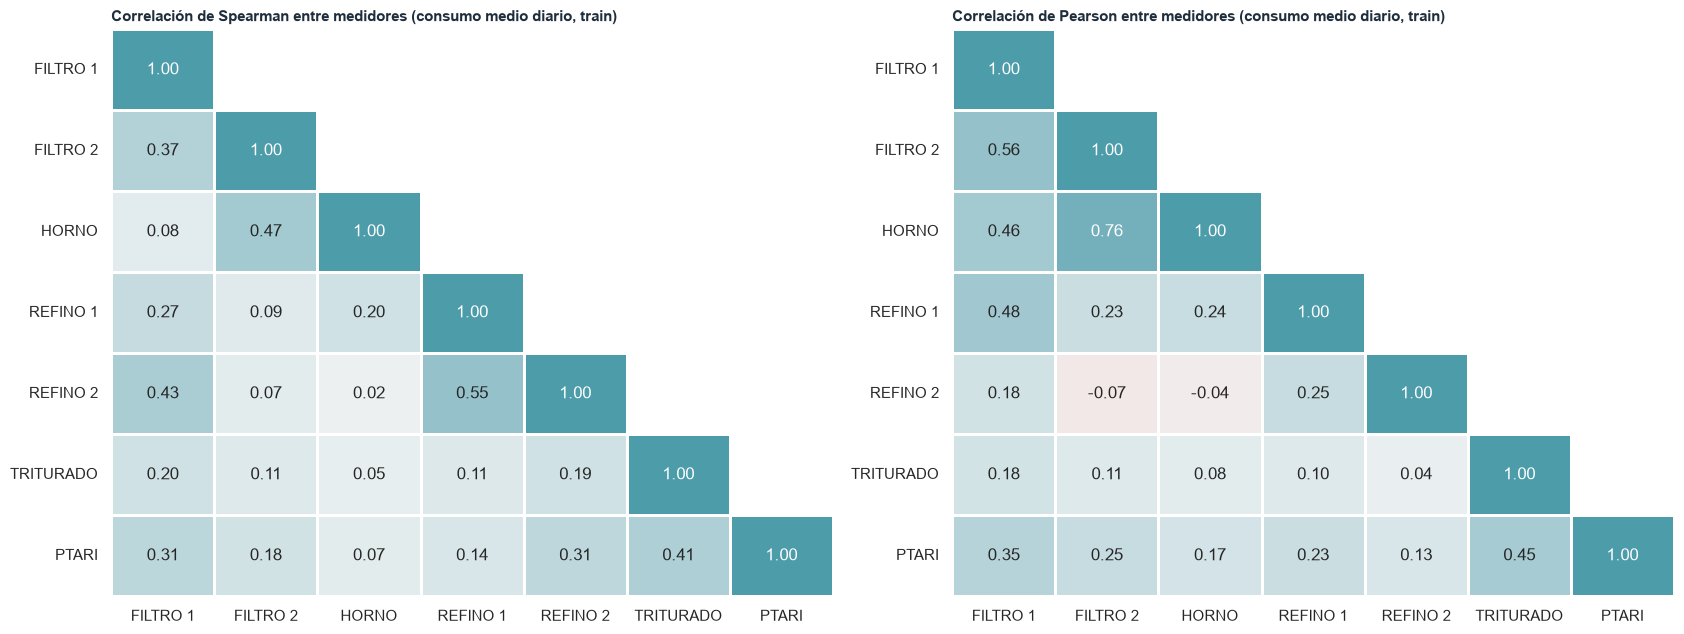

In [70]:
dia_ok = (
    train.index.to_series()
    .sub(pd.to_timedelta(train["paso_h"].fillna(1) / 2, unit="h"))
    .dt.normalize()
)
g = cons_ok[PROCESO].groupby(dia_ok)
diario = g.mean().where(
    g.count() >= MIN_HORAS_VALIDAS_DIA
)  # mínimo 12 horas válidas por día y medidor
n_completos = diario.dropna().shape[0]
print(f"Días con datos: {len(diario):,} · días completos (7 medidores): {n_completos:,}")

corr_s = diario.corr(method="spearman")
corr_p = diario.corr(method="pearson")
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
mask = np.triu(np.ones_like(corr_s, dtype=bool), 1)
cmap = sns.diverging_palette(15, 210, s=75, l=60, as_cmap=True)
for ax, c, nombre in zip(axes, [corr_s, corr_p], ["Spearman", "Pearson"], strict=True):
    sns.heatmap(
        c,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap=cmap,
        vmin=-1,
        vmax=1,
        center=0,
        linewidths=1,
        ax=ax,
        cbar=False,
    )
    ax.set_title(
        f"Correlación de {nombre} entre medidores (consumo medio diario, train)",
        loc="left",
        fontweight="bold",
        color=INK,
        fontsize=11,
    )
plt.tight_layout()
plt.show()

spearman  pearson  dif_s_p
medidor_a medidor_b                            
REFINO 1  REFINO 2       0.55     0.25     0.30
FILTRO 2  HORNO          0.47     0.76    -0.29
FILTRO 1  REFINO 2       0.43     0.18     0.25
TRITURADO PTARI          0.41     0.45    -0.04
FILTRO 1  FILTRO 2       0.37     0.56    -0.19
          PTARI          0.31     0.35    -0.04
REFINO 2  PTARI          0.31     0.13     0.18
FILTRO 1  REFINO 1       0.27     0.48    -0.22
          TRITURADO      0.20     0.18     0.02
HORNO     REFINO 1       0.20     0.24    -0.04

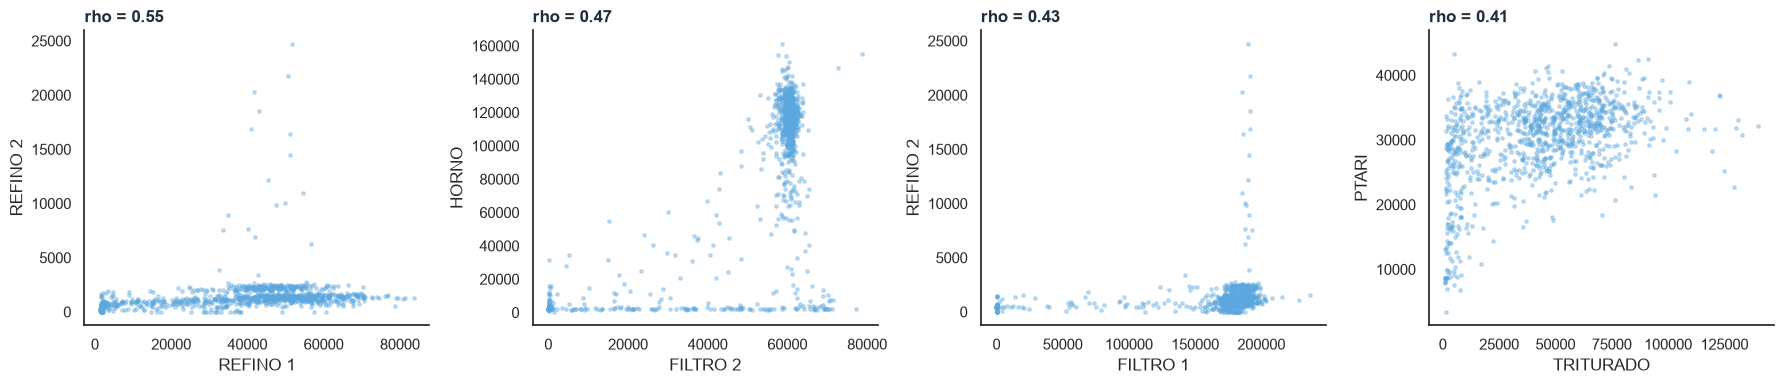

In [71]:
pares = (
    corr_s.where(np.triu(np.ones_like(corr_s, dtype=bool), 1)).stack().rename("spearman").to_frame()
)
pares["pearson"] = corr_p.stack().reindex(pares.index)
pares["dif_s_p"] = pares["spearman"] - pares["pearson"]
pares = pares.reindex(pares["spearman"].abs().sort_values(ascending=False).index)
pares.index.names = ["medidor_a", "medidor_b"]
display(pares.head(10))

top = pares.index[:4]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (a, b) in zip(axes, top, strict=True):
    ax.scatter(diario[a], diario[b], s=6, alpha=0.35, color="#5BA7DE")
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(
        f"rho = {pares.loc[(a, b), 'spearman']:.2f}", loc="left", fontweight="bold", color=INK
    )
    sns.despine(ax=ax)
plt.tight_layout()
plt.show()

In [72]:
# TOTAL_PROCESO se usa como "target" solo para excluirlo del cálculo.
# Sin cache_path → no escribe archivos.
diario_vif = diario.dropna().assign(TOTAL_PROCESO=lambda d: d.sum(axis=1))
vif = vif_table(diario_vif, target_variable="TOTAL_PROCESO", feature_variables=PROCESO)
display(vif)

,Variable,VIF,descartada,alto
0,FILTRO 2,2.84,None,False
1,HORNO,2.40,None,False
2,FILTRO 1,1.93,None,False
3,PTARI,1.41,None,False
4,REFINO 1,1.37,None,False
5,TRITURADO,1.26,None,False
6,REFINO 2,1.13,None,False


**Lectura final:**

- Las correlaciones entre medidores son moderadas (la mayor es REFINO 1 con REFINO 2, con ρ ~ 0.55). Esto indica que cada área de la planta tiene su propia dinámica operativa.

- En FILTRO 2 – HORNO Pearson es alto (~ 0.76) pero Spearman cae (~ 0.47). La relación lineal es engañosa y es generada por los estados de encendido/apagado (cuando el horno se apaga, el filtro baja con él), y no porque mantengan una proporción constante mientras operan.

- REFINO 2 Tiene un coeficiente de Spearman mucho mayor que el de Pearson con REFINO 1 y FILTRO 1. Esto significa que acompaña la operación general de la planta, pero presenta picos de consumo que rompen la linealidad.

- El Factor de Inflación de Varianza (VIF) es menor a 3 en todos los medidores. No hay información redundante grave, por lo que ninguna variable sobra para el modelado.

- TOTAL_PROCESO es la suma exacta de los 7 medidores. un modelo no debe incluir el total junto con todos sus componentes por la colinealidad perfecta.

## 9. Salud general de los datos (train)

In [73]:
salud = pd.DataFrame(
    {
        "% válido (ok)": (flag == "ok").mean() * 100,
        "% faltante estructural": flag.isin(["no_integrado"]).mean() * 100,
        "% faltante operativo": flag.isin(
            [
                "nan_archivo",
                "sin_lectura",
                "previa_invalida",
                "congelado",
                "recuperacion",
                "reinicio",
                "salto",
            ]
        ).mean()
        * 100,
        "% ruido de cuantización": (flag == "ruido_neg").mean() * 100,
        "% outliers Tukey (sobre ok)": outliers["% Tukey bajo"] + outliers["% Tukey alto"],
    }
)
salud["estado"] = np.select(
    [
        salud["% faltante estructural"] > PCT_ESTRUCTURAL,
        salud["% faltante operativo"] > PCT_REVISAR,
        salud["% faltante operativo"] > 1,
    ],
    ["usable solo desde su integración", "revisar", "aceptable"],
    "bueno",
)
display(salud)
print(
    f"Chequeos de esquema que fallan: {(esquema.estado == 'FALLA').sum()} → "
    + ", ".join(esquema.loc[esquema.estado == "FALLA", "chequeo"])
)

,% válido (ok),% faltante estructural,% faltante operativo,% ruido de cuantización,% outliers Tukey (sobre ok),estado
EMCALI,17.67,82.18,0.15,0.00,0.81,usable solo desde su integración
EDIF ADMON,17.66,82.00,0.33,0.00,2.48,usable solo desde su integración
FILTRO 1,97.32,0.00,2.61,0.07,10.70,aceptable
FILTRO 2,97.08,0.00,2.61,0.31,24.08,aceptable
HORNO,97.39,0.00,2.59,0.02,0.02,aceptable
REFINO 1,97.05,0.00,2.59,0.35,0.04,aceptable
REFINO 2,97.05,0.00,2.60,0.34,1.20,aceptable
TRITURADO,97.03,0.00,2.62,0.35,0.42,aceptable
PTARI,97.38,0.00,2.60,0.01,1.51,aceptable


Chequeos de esquema que fallan: 9 → EMCALI: acumulado no decreciente, EDIF ADMON: acumulado no decreciente, FILTRO 1: acumulado no decreciente, FILTRO 2: acumulado no decreciente, HORNO: acumulado no decreciente, REFINO 1: acumulado no decreciente, REFINO 2: acumulado no decreciente, TRITURADO: acumulado no decreciente, PTARI: acumulado no decreciente


## 10. Estrategia de manejo de faltantes (documentada, **no aplicada**)

| Problema en los datos | Causa probable | Solución principal (Tratamiento) | Plan B (Alternativas del modelo) |
| :--- | :--- | :--- | :--- |
| **Texto ilegible en Excel** (`nan_archivo`) | Error al exportar el archivo original desde la fuente. | Forzar la conversión del error a un dato vacío (NaN) y tratarlo como una lectura faltante. | N/A |
| **Medidores desconectados al inicio** (`no_integrado`) | Los medidores de EMCALI y Administración no existían o no estaban conectados antes de marzo 2026. | No inventar ni rellenar datos. Recortar el periodo del modelo a las fechas donde sí existen, o modelar esas áreas por separado. | Si se requiere analizar toda la historia desde el inicio, usar solo los medidores de las máquinas principales (proceso). |
| **Lectura faltante** (`sin_lectura` / `previa_invalida`) | Falla momentánea de comunicación con el medidor. | Dejar el consumo vacío (NaN) y crear una columna indicadora de "dato faltante". | Si el hueco es muy corto (máximo 2 horas), interpolar linealmente el acumulado (no el consumo) y recalcular la diferencia. |
| **SCADA congelado y salto de recuperación** (`congelado` + `recuperacion`) | El SCADA dejó de actualizar todos los medidores a la vez (MAR respecto al periodo) y luego registró de golpe el consumo acumulado. | Dejar vacías las horas congeladas y crear un indicador. Para totales, repartir el salto equitativamente entre las horas congeladas (así se conserva la energía). | Para el modelo: excluir ese bloque o rellenarlo con el perfil típico hora x día de la semana aprendido en train, escalado para que sume el total recuperado. |
| **Contador reiniciado** (`reinicio`) | Cambio del medidor o reinicio del contador. | Dejar vacía esa lectura (NaN). Para mantener continuo el acumulado, sumarle el último valor registrado antes del reinicio. | N/A |
| **Consumo negativo pequeño** (`ruido_neg`) | Límite de precisión del formato float32 con números muy grandes (cuantización). | Llevar el valor a 0, porque no es posible consumir energía negativa. | N/A |
| **Picos anómalos** (`salto`) | Lectura errónea del sistema (valor fuera de rango). | Dejar el valor vacío (NaN) y crear un indicador de salto. No recortarlo ni suavizarlo. | Si se puede, validar si ocurrió un evento extraordinario. |

- Al aplicar matemáticas para rellenar huecos (como interpolaciones), está estrictamente prohibido usar información que ocurra después de la fecha de corte. El modelo no puede usar datos del conjunto de prueba para "arreglar" el conjunto de entrenamiento.

- Las columnas que avisan que hubo un error o un dato vacío no se eliminan. Se conservan como variables oficiales, ya que enseñan al modelo a reaccionar ante los apagones o anomalías operativas de la planta.

Boceto de interfaz:
```python
class LimpiezaContadores(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):      # aprende medianas, tolerancias y umbrales SOLO con train
        ...
    def transform(self, X):        # deltas, categorías, indicadores; sin reajustar
        ...
```

## 11. Hallazgos principales (train: 21.044 filas, 80 %)

1. **Estructura sana:** la base tiene las columnas esperadas, con los tipos correctos y sin registros duplicados. Los únicos fallos del esquema vienen de que el acumulado a veces baja por reinicios del contador, pequeños negativos por precisión numérica y una última fila en cero.
2. **Precisión numérica:** el SCADA guarda las lecturas en `float32`, que con números tan grandes pierde precisión. El pipeline debe convertir a `float64` y tolerar esos pequeños desajustes para no confundirlos con errores reales.
3. **Por qué faltan datos:**
   * **Medidores nuevos:** a EMCALI y EDIF ADMON les falta ~82 % de la historia porque no estaban conectados al SCADA antes de marzo de 2026 (faltante estructural).
   * **Congelamientos del SCADA:** los medidores de proceso perdieron ~2,6 % de sus datos por periodos en que el SCADA dejó de actualizar todos los medidores a la vez (el más largo, entre julio y agosto de 2025, al cierre del FY25). El faltante depende del periodo y no de la hora (MAR).
4. **Desfase del reloj:** hay una lectura por hora, pero el minuto de registro cambia (de :31 a :30, y en las últimas filas :15, :01 y :46). Hay que alinear todos los registros a una grilla horaria.

5. **Patrones de consumo:** el consumo baja los domingos y lunes, en marzo-abril (paso del Q2 al Q3), y diciembre (cierre del Q1 fiscal), y justo antes de cada cambio de turno (05, 13 y 21 h).

6. **Los extremos no son errores:** las caídas a valores cercanos a cero, sobre todo en los filtros, son paradas reales y no deben borrarse. Solo los saltos extremos se marcan como `salto` o `recuperacion`.

7. **Ningún medidor sobra:** todos tienen VIF < 3, así que no hay redundancia. La relación entre medidores depende más de si se encienden y apagan juntos que de una proporción fija.

8. **Evolución por año fiscal (oct → sep):** la serie cubre FY24, FY25 y FY26 completos. El consumo de proceso estimado cayó de 3.910,7 M kWh (FY24) a 3.669,4 M (FY25, −6,2 %) y a 3.195,7 M (FY26, −12,9 %), y la intensidad bajó de 445 mil a 365 mil kWh/h. La caída del FY25 se concentra en su Q4 (jul–sep 2025), y la del FY26 en diciembre y marzo. HORNO gana participación (18,6 % → 22,2 %) porque las demás áreas caen, sobre todo REFINO 1 y TRITURADO. EMCALI y EDIF ADMON solo existen en FY26 y no se comparan entre años.

9. **Implicación para el modelado:** el consumo no es estable entre años fiscales: cae ~18 % entre FY24 y FY26, con efecto moderado (ε² = 0,07). Un modelo entrenado con toda la historia sin una variable de nivel (FY, tendencia o desfases largos) sobreestimará el FY26 y el FY27. Por lo mismo, la evaluación final debe ser cronológica (`SHUFFLE=False`, por ejemplo entrenar con FY24–FY25 y validar con FY26): con el split aleatorio actual, train y test comparten los tres años y el error se vería mejor de lo que será en producción.